In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
import shap

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# =========================
# 0) Variables to modify
# =========================

# ---- Input ----
# drug_name = "Dacomitinib"
# drug_smiles = "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN1CCCCC1"
# kinase_name = "P00533" #EGFR, use uniprot id

drug_name = "Imatinib"
drug_smiles = "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1"
kinase_name = "P00519" #ABL1, use uniprot id

# ---- klifs_file + klifs_sae (row-wise correspondence) ----
klifs_file_path = "../LSAE_embedding/kinase/human_482_typical_kinase_1955bit.csv"
kinase_name_col = "UniProt_ID"   # column name storing the short kinase name in klifs_file

# klifs_sae_path: one embedding per row (same order and length as klifs_file)
# Supported formats: .csv / .npy / .pt
klifs_sae_path = "../LSAE_embedding/Kinase_test_MCA/MCA_klifs_482_200D_features.csv"

# If klifs_sae is a CSV and the first row is a header/comment, set skiprows
klifs_sae_csv_skiprows = 1
klifs_sae_csv_header = None  # Usually the embedding CSV uses header=None

# ---- Molecular Morgan parameters (must match the training input of the molecular SAE) ----
radius = 2
nBits = 4096

# ---- Molecular SAE model path ----
mol_sae_model_path = "../LSAE_embedding/mol/LSAE_1900k_chembl_model_2.pt"
mol_sae_idx_path = "../LSAE_embedding/mol/LSAE_chembl_1900k_topk_of1024d_top99_2.pt"

# ---- Protein SAE configuration ----
# prot_sae_model_path = r"../LSAE_embedding/kinase/LSAE_482_kinases_klifs_512d_2.pt"
# prot_sae_idx_path = r"../LSAE_embedding/kinase/LSAE_klifs_482_kinases_topk_of512d_idx_99_2.pt"
klifs_onehot_path = r"../LSAE_embedding/kinase/human_482_typical_kinase_1955bit_onehot.csv"

# ---- Downstream XGBoost model (JSON) ----
xgb_model_json_path = "../model/KinSPEC_full_training_pool_MCA_200D.json"

# ---- Feature-dimension truncation used downstream ----
mol_keep_dims = 466     # e.g., 1024 -> first 467; set to None for no truncation

# Whether to truncate the protein embedding (usually not needed)
prot_keep_dims = None   # e.g., 200 -> None; or set to 150 if you want the first 150 dimensions

# ---- SHAP settings ----
topk_show = 30
background_size = 500    # Prefer using the real training set as background; here a runnable zero-vector background is provided

# ---- Output directory ----
outdir = f"./Linear_SAE_xgb_shap_{kinase_name}_{drug_name}"
os.makedirs(outdir, exist_ok=True)

# =========================
# config: choose BitScore calculation method
# =========================

# BitScore
BITSCORE_METHOD = "normalized_with_z"  # optional: "normalized_with_z", "normalized_no_z", "simple_abs"

# if calculate signed version(mechanistic explaination)
COMPUTE_SIGNED_BITSCORE = True

print(f"\n{'='*60}")
print(f"BitScore Calculation Configuration")
print(f"{'='*60}")
print(f"Method: {BITSCORE_METHOD}")
print(f"Compute signed version: {COMPUTE_SIGNED_BITSCORE}")
print(f"{'='*60}")

# =========================
# 1) SAE Model Definition
# =========================
class SparseLinearAE(nn.Module):
    def __init__(self, input_dim=4096, latent_dim=1024):
        super().__init__()
        self.encoder = nn.Linear(input_dim, latent_dim, bias=True)
        self.decoder = nn.Linear(latent_dim, input_dim, bias=True)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

# =========================
# 2) Load mol LSAE model
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model
mol_sae_model = SparseLinearAE(input_dim=nBits, latent_dim=1024).to(device)
checkpoint = torch.load(mol_sae_model_path, map_location=device, weights_only=True)
mol_sae_model.load_state_dict(checkpoint)
mol_sae_model.eval()

# Load latent indices
keep_idx = torch.load(mol_sae_idx_path, map_location=device, weights_only=True).long()
if mol_keep_dims is not None:
    keep_idx = keep_idx[:mol_keep_dims]

print(f"Loaded SAE model with {len(keep_idx)} latent dimensions on {device}")

# extract decoder weight
mol_Wdec = mol_sae_model.decoder.weight.detach().cpu().numpy()  # (4096, 1024)

# keep selected latent's decoder column
mol_Wdec_selected = mol_Wdec[:, keep_idx.cpu().numpy()]  # (4096, mol_keep_dims)

# =========================
# 3) Morgan_generator (with BitInfoMap)
# =========================
def Morgan_generator(smiles, radius, nBits):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError("Invalid SMILES string")
    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nBits)
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    ao.CollectAtomToBits()
    ao.CollectAtomCounts()
    fp = morgan_gen.GetFingerprint(mol, additionalOutput=ao)
    BitInfoMap = ao.GetBitInfoMap()
    AtomToBits = ao.GetAtomToBits()
    AtomCounts = ao.GetAtomCounts()
    return fp, BitInfoMap, AtomToBits, AtomCounts, mol

# =========================
# 4) kinase embedding: kinase_name -> klifs_file row num -> klifs_LSAE feature
# =========================

klifs_df = pd.read_csv(klifs_file_path)
if kinase_name_col not in klifs_df.columns:
    raise KeyError(f"'{kinase_name_col}' not found in klifs_file. Columns: {klifs_df.columns.tolist()}")

hit_rows = klifs_df.index[klifs_df[kinase_name_col].astype(str) == str(kinase_name)].tolist()
if len(hit_rows) == 0:
    examples = klifs_df[kinase_name_col].dropna().astype(str).unique()[:30]
    raise KeyError(f"Kinase '{kinase_name}' not found in klifs_file. Examples: {examples}")

if len(hit_rows) > 1:
    print(f"[WARN] Found multiple rows for kinase '{kinase_name}': {hit_rows[:10]} ... using the first.")
row_idx = int(hit_rows[0])
print("Matched row_idx in klifs_file:", row_idx)

# load klifs_sae embedding matrix
ext = os.path.splitext(klifs_sae_path)[1].lower()

if ext == ".csv":
    klifs_sae_mat = pd.read_csv(
        klifs_sae_path,
        skiprows=klifs_sae_csv_skiprows,
        header=klifs_sae_csv_header
    ).values.astype(np.float32)
elif ext == ".npy":
    klifs_sae_mat = np.load(klifs_sae_path).astype(np.float32)
elif ext == ".pt":
    t = torch.load(klifs_sae_path, map_location="cpu")
    if isinstance(t, torch.Tensor):
        klifs_sae_mat = t.detach().cpu().numpy().astype(np.float32)
    else:
        for key in ["emb", "embedding", "X", "features"]:
            if key in t:
                klifs_sae_mat = t[key].detach().cpu().numpy().astype(np.float32)
                break
        else:
            raise TypeError("Unsupported .pt content: not a Tensor and no known keys found.")
else:
    raise ValueError(f"Unsupported klifs_sae_path extension: {ext}")

if klifs_sae_mat.shape[0] != len(klifs_df):
    print(f"[WARN] Row count mismatch: klifs_sae_mat rows={klifs_sae_mat.shape[0]} vs klifs_file rows={len(klifs_df)}")
    print("       If you filtered/removed duplicates in one file but not the other, mapping will be wrong.")

if row_idx < 0 or row_idx >= klifs_sae_mat.shape[0]:
    raise IndexError(f"row_idx={row_idx} out of range for klifs_sae_mat with shape {klifs_sae_mat.shape}")

prot_emb = klifs_sae_mat[row_idx].reshape(-1).astype(np.float32)
if prot_keep_dims is not None:
    prot_emb_used = prot_emb[:prot_keep_dims].astype(np.float32)
else:
    prot_emb_used = prot_emb

print("Protein embedding shape:", prot_emb.shape, "used:", prot_emb_used.shape)

# =========================
# 5) mol Morgan fp -> mol LSAE embedding
# =========================

fp, BitInfoMap, AtomToBits, AtomCounts, mol = Morgan_generator(drug_smiles, radius=radius, nBits=nBits)

# convert to numpy array
mol_fp = np.zeros((nBits,), dtype=np.float32)
mol_fp[list(fp.GetOnBits())] = 1.0
mol_fp_active = mol_fp.astype(np.uint8)

# use model extract embedding
mol_fp_tensor = torch.from_numpy(mol_fp).float().unsqueeze(0).to(device)

with torch.no_grad():
    mol_emb_full = mol_sae_model.encoder(mol_fp_tensor)  # (1, 1024)
    mol_emb = mol_emb_full[:, keep_idx].cpu().numpy().squeeze()  # (mol_keep_dims,)

mol_emb_used = mol_emb.astype(np.float32)

print("Mol embedding shape:", mol_emb_used.shape)



/home/s1856122/anaconda3/envs/xgboost/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



BitScore Calculation Configuration
Method: normalized_with_z
Compute signed version: True
Loaded SAE model with 466 latent dimensions on cpu
Matched row_idx in klifs_file: 156
Protein embedding shape: (200,) used: (200,)
Mol embedding shape: (466,)


In [2]:
# =========================
# 6) concat -> XGBoost pred
# =========================
X_one = np.hstack([mol_emb_used, prot_emb_used]).reshape(1, -1).astype(np.float32)
feature_names = list(range(X_one.shape[1]))  
X_one_df = pd.DataFrame(X_one, columns=feature_names)
print("Final X shape:", X_one.shape)

booster = xgb.Booster()
booster.load_model(xgb_model_json_path)
pred = booster.predict(xgb.DMatrix(X_one_df))
print("Prediction:", pred)

Final X shape: (1, 666)


Prediction: [0.9881186]


In [3]:
# =========================
# Configuration: SHAP feature selection
# =========================

# ---- Top-k feature selection by absolute SHAP ----
mol_topk_for_analysis = 5      # use top-5 molecule latents
prot_topk_for_analysis = 5     # use top-5 protein MCA components



SHAP Analysis with Molecule Top-K + Protein Top-K



SHAP Feature Selection Results
Molecule latents:
  - Selection: top 5 by |SHAP|
  - For analysis: 5 / 466
  - SHAP range: [0.0000, 1.1033]
  - Important latents: [8, 9, 307, 10, 2]
  - Important latent |SHAP|: [1.1033, 0.805, 0.6891, 0.5549, 0.4422]

Protein/kinase MCA components:
  - Selection: top 5 by |SHAP|
  - For analysis: 5 / 200
  - SHAP range: [0.0000, 0.4983]
  - Important components: [3, 2, 51, 167, 33]
  - Important component |SHAP|: [0.4983, 0.3977, 0.2055, 0.1574, 0.1533]

[save] SHAP table → ./Linear_SAE_xgb_shap_P00519_Imatinib/top_features_single_sample_by_SHAP.csv


,feature_index,feature_name,shap_value,abs_shap,feature_value,selected_for_analysis
0,8,mol_z_8,1.103343,1.103343,-0.178824,True
1,9,mol_z_9,0.805014,0.805014,-0.271345,True
2,307,mol_z_307,0.689060,0.689060,0.069512,True
3,10,mol_z_10,-0.554885,0.554885,-0.139489,True
4,469,prot_e_3,0.498293,0.498293,0.545306,True
5,2,mol_z_2,0.442189,0.442189,0.136522,True
6,19,mol_z_19,-0.434645,0.434645,-0.079741,False
7,11,mol_z_11,0.428406,0.428406,0.158995,False
8,468,prot_e_2,0.397742,0.397742,-0.263951,True
9,352,mol_z_352,0.373409,0.373409,-0.061709,False


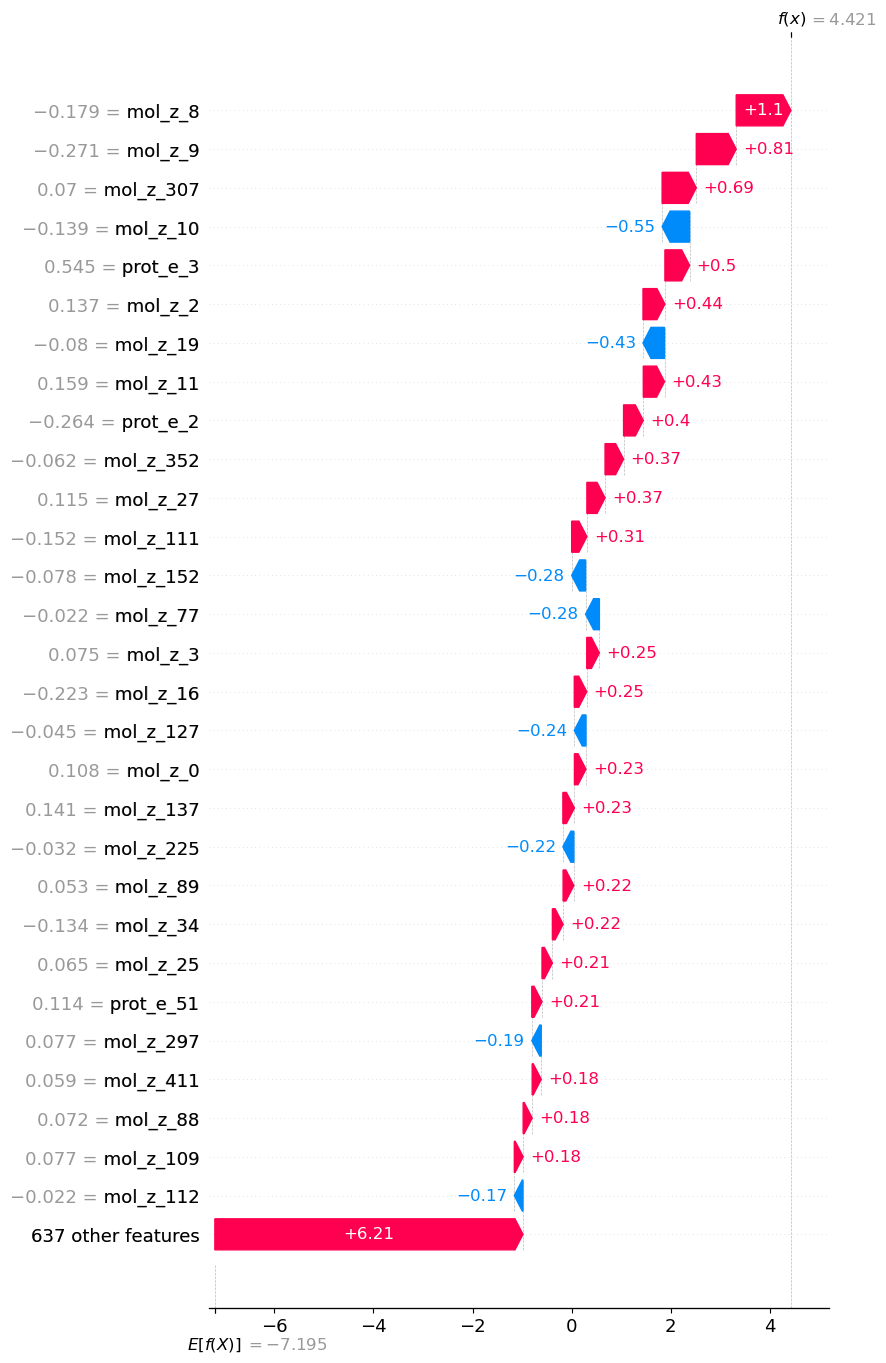


Molecule Inverse Mapping - Corrected BitScore
Formula: BitScore_j = b_j × Σ_k |SHAP_k| × |z_k| × |W_{j,k}|
[info] Analyzing 5 important molecule latents
[info] Molecule latent values shape: (466,)
[info] Molecule latent range: [-0.2713, 0.2161]
  Latent 8: SHAP=1.1033, z=-0.1788, contribution=3.5960
  Latent 9: SHAP=0.8050, z=-0.2713, contribution=4.4808
  Latent 307: SHAP=0.6891, z=0.0695, contribution=0.4336

[info] Molecule BitScore (with z_k) range: [0.000000, 0.483584]
[info] Non-zero BitScores: 65
[info] Found 65 substructures
[save] Molecule substructure BitScore → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_substructure_bitscore_corrected.csv

Top 10 molecule substructures (corrected BitScore):


,center_atom,radius,bit,bitscore,rank,num_contributing_latents,top_3_latents
0,26,1,3500,0.483584,1,5,"9,8,10"
1,26,0,378,0.415324,2,5,"9,8,10"
2,5,0,3200,0.404693,3,5,"8,9,10"
3,14,0,2974,0.371262,4,5,"9,8,10"
4,0,0,3105,0.367123,5,5,"9,8,10"
5,6,0,2855,0.359721,6,5,"9,8,2"
6,12,0,2128,0.352991,7,5,"9,8,2"
7,7,0,2698,0.344953,8,5,"9,8,2"
8,22,1,875,0.343838,9,5,"8,9,10"
9,13,0,2983,0.340573,10,5,"8,9,10"


In [4]:
# =========================
# 6) SHAP: single sample important feature position (mol_z_i / prot_e_j)
#    Molecule and protein/kinase both use top-k selection.
# =========================

print(f"\n{'='*60}")
print(f"SHAP Analysis with Molecule Top-K + Protein Top-K")
print(f"{'='*60}")

mol_dim = mol_emb_used.shape[0]
prot_dim = prot_emb_used.shape[0]
feat_names = [f"mol_z_{i}" for i in range(mol_dim)] + [f"prot_e_{j}" for j in range(prot_dim)]

background = np.zeros((min(background_size, 50), X_one.shape[1]), dtype=np.float32)
explainer = shap.TreeExplainer(booster, data=background)
shap_values = explainer.shap_values(X_one)

if isinstance(shap_values, list):
    sv = shap_values[1] if len(shap_values) > 1 else shap_values[0]
elif getattr(shap_values, "ndim", 0) == 3:
    sv = shap_values[:, :, 1] if shap_values.shape[2] > 1 else shap_values[:, :, 0]
else:
    sv = shap_values

sv = np.array(sv).reshape(-1)
abs_sv = np.abs(sv)

# split the SHAP of mol and kinase
mol_shap_values = sv[:mol_dim]
prot_shap_values = sv[mol_dim:]

mol_abs_shap = np.abs(mol_shap_values)
prot_abs_shap = np.abs(prot_shap_values)

# molecule: top-k selection by absolute SHAP
important_mol_indices = np.argsort(-mol_abs_shap)[:mol_topk_for_analysis]
important_mol_latents = important_mol_indices.tolist()

# protein/kinase: top-k selection by absolute SHAP
important_prot_indices = np.argsort(-prot_abs_shap)[:prot_topk_for_analysis]
important_prot_latents = important_prot_indices.tolist()

print(f"\n{'='*60}")
print(f"SHAP Feature Selection Results")
print(f"{'='*60}")
print(f"Molecule latents:")
print(f"  - Selection: top {mol_topk_for_analysis} by |SHAP|")
print(f"  - For analysis: {len(important_mol_latents)} / {mol_dim}")
print(f"  - SHAP range: [{mol_abs_shap.min():.4f}, {mol_abs_shap.max():.4f}]")
print(f"  - Important latents: {important_mol_latents}")
print(f"  - Important latent |SHAP|: {[round(float(mol_abs_shap[i]), 4) for i in important_mol_latents]}")

print(f"\nProtein/kinase MCA components:")
print(f"  - Selection: top {prot_topk_for_analysis} by |SHAP|")
print(f"  - For analysis: {len(important_prot_latents)} / {prot_dim}")
print(f"  - SHAP range: [{prot_abs_shap.min():.4f}, {prot_abs_shap.max():.4f}]")
print(f"  - Important components: {important_prot_latents}")
print(f"  - Important component |SHAP|: {[round(float(prot_abs_shap[i]), 4) for i in important_prot_latents]}")

# construct complete SHAP result list
top_idx = np.argsort(-abs_sv)[:topk_show]

df_shap = pd.DataFrame({
    "feature_index": top_idx,
    "feature_name": [feat_names[i] for i in top_idx],
    "shap_value": sv[top_idx],
    "abs_shap": abs_sv[top_idx],
    "feature_value": X_one.reshape(-1)[top_idx],
    "selected_for_analysis": [
        (i < mol_dim and i in important_mol_latents) or 
        (i >= mol_dim and (i - mol_dim) in important_prot_latents)
        for i in top_idx
    ]
}).sort_values("abs_shap", ascending=False)

shap_csv = os.path.join(outdir, "top_features_single_sample_by_SHAP.csv")
df_shap.to_csv(shap_csv, index=False)
print(f"\n[save] SHAP table → {shap_csv}")
display(df_shap)

exp = shap.Explanation(
    values=sv,
    base_values=explainer.expected_value if np.isscalar(explainer.expected_value) else explainer.expected_value[0],
    data=X_one.reshape(-1),
    feature_names=feat_names
)
shap.plots.waterfall(exp, max_display=topk_show)

# =========================
# 7) mol inverse mapping
# =========================

print(f"\n{'='*60}")
print(f"Molecule Inverse Mapping - Corrected BitScore")
print(f"Formula: BitScore_j = b_j × Σ_k |SHAP_k| × |z_k| × |W_{{j,k}}|")
print(f"{'='*60}")

# check if mol have important latent
if len(important_mol_latents) == 0:
    print("[ERROR] No important molecule latents found!")
    print(f"[INFO] Check mol_topk_for_analysis (current: {mol_topk_for_analysis})")
else:
    print(f"[info] Analyzing {len(important_mol_latents)} important molecule latents")
    
    # obtain the mol latent value
    mol_z_values = mol_emb_used  # shape: (467,)
    
    print(f"[info] Molecule latent values shape: {mol_z_values.shape}")
    print(f"[info] Molecule latent range: [{mol_z_values.min():.4f}, {mol_z_values.max():.4f}]")
    
    # ---- bitscore with z_k
    bit_bitscore_mol = np.zeros(nBits, dtype=np.float64)
    
    for idx, lx in enumerate(important_mol_latents):
        if lx < 0 or lx >= mol_Wdec_selected.shape[1]:
            continue
        
        # SHAP value at selected space
        s_k = mol_shap_values[lx]
        
        # latent_k value
        z_k = mol_z_values[lx]
        
        # Decoder weight at selected latent
        W_k = mol_Wdec_selected[:, lx]  # shape: (4096,)
        
        # cumulated attribution: b_j x |SHAP_k| x |z_k| x |W_{j,k}|
        bit_bitscore_mol += mol_fp_active * np.abs(s_k) * np.abs(z_k) * np.abs(W_k)
        
        if idx < 3:  # print top 3 latent
            contribution = np.sum(mol_fp_active * np.abs(s_k) * np.abs(z_k) * np.abs(W_k))
            print(f"  Latent {lx}: SHAP={s_k:.4f}, z={z_k:.4f}, contribution={contribution:.4f}")
    
    print(f"\n[info] Molecule BitScore (with z_k) range: [{bit_bitscore_mol.min():.6f}, {bit_bitscore_mol.max():.6f}]")
    print(f"[info] Non-zero BitScores: {np.sum(bit_bitscore_mol > 0)}")
    
    # ---- constract substructure info ----
    active_bits_with_score = np.where((mol_fp_active == 1) & (bit_bitscore_mol > 0))[0]
    
    if len(active_bits_with_score) == 0:
        print("[WARN] No bits with BitScore > 0 found!")
        print("[INFO] This might indicate:")
        print("       1. All selected latents have very small z_k values")
        print("       2. Selected molecule top-k latents have very small contribution")
        print("       3. Decoder weights are very small for active bits")
    else:
        sorted_bit_indices = np.argsort(-bit_bitscore_mol[active_bits_with_score])
        sorted_bits = active_bits_with_score[sorted_bit_indices]
        sorted_scores = bit_bitscore_mol[sorted_bits]
        
        all_important_info_mol = {}
        
        for rank, bit in enumerate(sorted_bits):
            bit = int(bit)
            if bit not in BitInfoMap:
                continue
            
            atom_idx, rad_used = BitInfoMap[bit][0]
            key = (int(atom_idx), int(rad_used), bit)
            
            # calucate bit contribution at latent level
            latent_contributions = []
            for lx in important_mol_latents:
                if lx < mol_Wdec_selected.shape[1]:
                    s_k = mol_shap_values[lx]
                    z_k = mol_z_values[lx]
                    W_jk = mol_Wdec_selected[bit, lx]
                    
                    contribution = mol_fp_active[bit] * np.abs(s_k) * np.abs(z_k) * np.abs(W_jk)
                    if contribution > 1e-8:
                        latent_contributions.append({
                            'latent': lx,
                            'shap': s_k,
                            'z': z_k,
                            'weight': W_jk,
                            'contribution': contribution
                        })
            
            # ranking
            latent_contributions.sort(key=lambda x: x['contribution'], reverse=True)
            
            all_important_info_mol[key] = {
                "bit": bit,
                "bitscore": float(sorted_scores[rank]),
                "rank": rank + 1,
                "latent_contributions": latent_contributions,
                "top_3_latents": [lc['latent'] for lc in latent_contributions[:3]],
                "num_contributing_latents": len(latent_contributions)
            }
        
        print(f"[info] Found {len(all_important_info_mol)} substructures")
        
        # ---- create DataFrame ----
        substructure_importance_mol = []
        for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
            substructure_importance_mol.append({
                "center_atom": atom_idx,
                "radius": rad_used,
                "bit": bit,
                "bitscore": info["bitscore"],
                "rank": info["rank"],
                "num_contributing_latents": info["num_contributing_latents"],
                "top_3_latents": ",".join(map(str, info["top_3_latents"]))
            })
        
        df_substruct_mol = pd.DataFrame(substructure_importance_mol).sort_values("bitscore", ascending=False)
        substruct_csv_mol = os.path.join(outdir, "mol_substructure_bitscore_corrected.csv")
        df_substruct_mol.to_csv(substruct_csv_mol, index=False)
        print(f"[save] Molecule substructure BitScore → {substruct_csv_mol}")
        
        print("\nTop 10 molecule substructures (corrected BitScore):")
        display(df_substruct_mol.head(10))

In [5]:
def atoms_bonds_for_environment(mol, center_atom, radius):
    """Get the atoms and bonds within the specified radius around a given atom"""
    if radius == 0:
        return [center_atom], []
    
    
    # Manual implementation of breadth-first search
    atom_ids = {center_atom}
    bond_ids = set()
    current_layer = {center_atom}
    
    for _ in range(radius):
        next_layer = set()
        for atom_idx in current_layer:
            atom = mol.GetAtomWithIdx(atom_idx)
            for neighbor in atom.GetNeighbors():
                neighbor_idx = neighbor.GetIdx()
                bond = mol.GetBondBetweenAtoms(atom_idx, neighbor_idx)
                if bond is not None:
                    bond_idx = bond.GetIdx()
                    if bond_idx not in bond_ids:
                        bond_ids.add(bond_idx)
                        if neighbor_idx not in atom_ids:
                            next_layer.add(neighbor_idx)
                            atom_ids.add(neighbor_idx)
        current_layer = next_layer
        if not current_layer:
            break
    
    return sorted(atom_ids), sorted(bond_ids)


In [6]:
# =========================
# 7) Molecular inverse mapping - improved version (normalised attribution + signed version)
# =========================

print(f"\n{'='*60}")
print(f"Molecule Inverse Mapping - Improved BitScore")
print(f"{'='*60}")

if len(important_mol_latents) == 0:
    print("[ERROR] No important molecule latents found!")
else:
    print(f"[info] Analyzing {len(important_mol_latents)} important molecule latents")
    
    mol_z_values = mol_emb_used
    
    print(f"[info] Molecule latent values shape: {mol_z_values.shape}")
    print(f"[info] Molecule latent range: [{mol_z_values.min():.4f}, {mol_z_values.max():.4f}]")
    
    # ---- Calculate BitScore (multiple versions)----
    
    # 1. Unsigned BitScore（used for importance ranking）
    bit_bitscore_mol_unsigned = np.zeros(nBits, dtype=np.float64)
    
    # 2. Signed BitScore（used for directional interpretation）
    if COMPUTE_SIGNED_BITSCORE:
        bit_bitscore_mol_signed = np.zeros(nBits, dtype=np.float64)
    
    # Select the calculation method
    if BITSCORE_METHOD == "normalized_with_z":
        # Method 1: normalised attribution (including z_k)
        # A_j = Σ_k φ_k × (|z_k|×|W_{j,k}|) / Σ_{j'} (|z_k|×|W_{j',k}|)
        
        print("[info] Using normalized attribution with z_k")
        
        for lx in important_mol_latents:
            if lx < 0 or lx >= mol_Wdec_selected.shape[1]:
                continue
            
            s_k = mol_shap_values[lx]  # SHAP (φ_k)
            z_k = mol_z_values[lx]     # latent activation
            W_k = mol_Wdec_selected[:, lx]  # decoder weights
            
            # Calculate the total loading of this latent across all active bits
            weighted_loading = mol_fp_active * np.abs(z_k) * np.abs(W_k)
            total_loading = np.sum(weighted_loading)
            
            if total_loading > 1e-10:  # avoid division by zero
                # Normalised attribution
                normalized_weight = weighted_loading / total_loading
                
                # Unsigned: use |φ_k|
                bit_bitscore_mol_unsigned += np.abs(s_k) * normalized_weight
                
                # Signed: preserve the sign of φ_k
                if COMPUTE_SIGNED_BITSCORE:
                    bit_bitscore_mol_signed += s_k * normalized_weight
    
    elif BITSCORE_METHOD == "normalized_no_z":
        # Method 2: normalised attribution (without z_k)
        # A_j = Σ_k φ_k × |W_{j,k}| / Σ_{j'} |W_{j',k}|
        
        print("[info] Using normalized attribution without z_k")
        
        for lx in important_mol_latents:
            if lx < 0 or lx >= mol_Wdec_selected.shape[1]:
                continue
            
            s_k = mol_shap_values[lx]
            W_k = mol_Wdec_selected[:, lx]
            
            weighted_loading = mol_fp_active * np.abs(W_k)
            total_loading = np.sum(weighted_loading)
            
            if total_loading > 1e-10:
                normalized_weight = weighted_loading / total_loading
                
                bit_bitscore_mol_unsigned += np.abs(s_k) * normalized_weight
                
                if COMPUTE_SIGNED_BITSCORE:
                    bit_bitscore_mol_signed += s_k * normalized_weight
    
    else:  # "simple_abs"
        # Method 3: simple multiplication (original method, for comparison)
        # A_j = b_j × Σ_k |φ_k| × |z_k| × |W_{j,k}|
        
        print("[info] Using simple absolute product (for comparison)")
        
        for lx in important_mol_latents:
            if lx < 0 or lx >= mol_Wdec_selected.shape[1]:
                continue
            
            s_k = mol_shap_values[lx]
            z_k = mol_z_values[lx]
            W_k = mol_Wdec_selected[:, lx]
            
            bit_bitscore_mol_unsigned += mol_fp_active * np.abs(s_k) * np.abs(z_k) * np.abs(W_k)
            
            if COMPUTE_SIGNED_BITSCORE:
                bit_bitscore_mol_signed += mol_fp_active * s_k * z_k * W_k
    
    # Print contribution validation for the first three latents
    print("\nLatent contribution verification:")
    for idx, lx in enumerate(important_mol_latents[:3]):
        if lx < mol_Wdec_selected.shape[1]:
            s_k = mol_shap_values[lx]
            z_k = mol_z_values[lx]
            W_k = mol_Wdec_selected[:, lx]
            
            if BITSCORE_METHOD.startswith("normalized"):
                weighted_loading = mol_fp_active * np.abs(z_k) * np.abs(W_k) if "with_z" in BITSCORE_METHOD else mol_fp_active * np.abs(W_k)
                total_loading = np.sum(weighted_loading)
                print(f"  Latent {lx}: SHAP={s_k:.4f}, z={z_k:.4f}, total_loading={total_loading:.4f}")
            else:
                contribution = np.sum(mol_fp_active * np.abs(s_k) * np.abs(z_k) * np.abs(W_k))
                print(f"  Latent {lx}: SHAP={s_k:.4f}, z={z_k:.4f}, contribution={contribution:.4f}")
    
    print(f"\n[info] Unsigned BitScore range: [{bit_bitscore_mol_unsigned.min():.6f}, {bit_bitscore_mol_unsigned.max():.6f}]")
    print(f"[info] Non-zero unsigned BitScores: {np.sum(bit_bitscore_mol_unsigned > 0)}")
    
    if COMPUTE_SIGNED_BITSCORE:
        print(f"[info] Signed BitScore range: [{bit_bitscore_mol_signed.min():.6f}, {bit_bitscore_mol_signed.max():.6f}]")
        positive_bits = np.sum(bit_bitscore_mol_signed > 0)
        negative_bits = np.sum(bit_bitscore_mol_signed < 0)
        print(f"[info] Signed BitScores: {positive_bits} positive, {negative_bits} negative")
    
    # ---- Build substructure information (rank by unsigned values while retaining signed information)----
    active_bits_with_score = np.where((mol_fp_active == 1) & (bit_bitscore_mol_unsigned > 0))[0]
    
    if len(active_bits_with_score) == 0:
        print("[WARN] No bits with BitScore > 0 found!")
    else:
        # Sort by unsigned BitScore (importance)
        sorted_bit_indices = np.argsort(-bit_bitscore_mol_unsigned[active_bits_with_score])
        sorted_bits = active_bits_with_score[sorted_bit_indices]
        sorted_scores_unsigned = bit_bitscore_mol_unsigned[sorted_bits]
        sorted_scores_signed = bit_bitscore_mol_signed[sorted_bits] if COMPUTE_SIGNED_BITSCORE else None
        
        all_important_info_mol = {}
        
        for rank, bit in enumerate(sorted_bits):
            bit = int(bit)
            if bit not in BitInfoMap:
                continue
            
            atom_idx, rad_used = BitInfoMap[bit][0]
            key = (int(atom_idx), int(rad_used), bit)
            
            # Calculate the latent-level contribution of this bit (unsigned and signed)
            latent_contributions_unsigned = []
            latent_contributions_signed = [] if COMPUTE_SIGNED_BITSCORE else None
            
            for lx in important_mol_latents:
                if lx < mol_Wdec_selected.shape[1]:
                    s_k = mol_shap_values[lx]
                    z_k = mol_z_values[lx]
                    W_jk = mol_Wdec_selected[bit, lx]
                    
                    if BITSCORE_METHOD.startswith("normalized"):
                        # Recalculate the normalised weights
                        W_k = mol_Wdec_selected[:, lx]
                        if "with_z" in BITSCORE_METHOD:
                            weighted_loading = mol_fp_active * np.abs(z_k) * np.abs(W_k)
                        else:
                            weighted_loading = mol_fp_active * np.abs(W_k)
                        
                        total_loading = np.sum(weighted_loading)
                        
                        if total_loading > 1e-10:
                            if "with_z" in BITSCORE_METHOD:
                                normalized_weight_j = (np.abs(z_k) * np.abs(W_jk)) / total_loading
                            else:
                                normalized_weight_j = np.abs(W_jk) / total_loading
                            
                            contrib_unsigned = np.abs(s_k) * normalized_weight_j
                            contrib_signed = s_k * normalized_weight_j if COMPUTE_SIGNED_BITSCORE else 0
                        else:
                            contrib_unsigned = 0
                            contrib_signed = 0
                    else:
                        contrib_unsigned = mol_fp_active[bit] * np.abs(s_k) * np.abs(z_k) * np.abs(W_jk)
                        contrib_signed = mol_fp_active[bit] * s_k * z_k * W_jk if COMPUTE_SIGNED_BITSCORE else 0
                    
                    if contrib_unsigned > 1e-8:
                        latent_contributions_unsigned.append({
                            'latent': lx,
                            'shap': s_k,
                            'z': z_k,
                            'weight': W_jk,
                            'contribution': contrib_unsigned
                        })
                        
                        if COMPUTE_SIGNED_BITSCORE:
                            latent_contributions_signed.append({
                                'latent': lx,
                                'shap': s_k,
                                'z': z_k,
                                'weight': W_jk,
                                'contribution': contrib_signed
                            })
            
            # Sort by contribution
            latent_contributions_unsigned.sort(key=lambda x: x['contribution'], reverse=True)
            if COMPUTE_SIGNED_BITSCORE:
                latent_contributions_signed.sort(key=lambda x: abs(x['contribution']), reverse=True)
            
            all_important_info_mol[key] = {
                "bit": bit,
                "bitscore_unsigned": float(sorted_scores_unsigned[rank]),
                "bitscore_signed": float(sorted_scores_signed[rank]) if COMPUTE_SIGNED_BITSCORE else None,
                "rank": rank + 1,
                "latent_contributions_unsigned": latent_contributions_unsigned,
                "latent_contributions_signed": latent_contributions_signed if COMPUTE_SIGNED_BITSCORE else None,
                "top_3_latents": [lc['latent'] for lc in latent_contributions_unsigned[:3]],
                "num_contributing_latents": len(latent_contributions_unsigned)
            }
        
        print(f"[info] Found {len(all_important_info_mol)} substructures")
        
        # ---- Build DataFrame ----
        substructure_importance_mol = []
        for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
            record = {
                "center_atom": atom_idx,
                "radius": rad_used,
                "bit": bit,
                "bitscore_unsigned": info["bitscore_unsigned"],
                "rank": info["rank"],
                "num_contributing_latents": info["num_contributing_latents"],
                "top_3_latents": ",".join(map(str, info["top_3_latents"]))
            }
            
            if COMPUTE_SIGNED_BITSCORE:
                record["bitscore_signed"] = info["bitscore_signed"]
                record["direction"] = "positive" if info["bitscore_signed"] > 0 else "negative"
            
            substructure_importance_mol.append(record)
        
        df_substruct_mol = pd.DataFrame(substructure_importance_mol).sort_values("bitscore_unsigned", ascending=False)
        substruct_csv_mol = os.path.join(outdir, f"mol_substructure_bitscore_{BITSCORE_METHOD}.csv")
        df_substruct_mol.to_csv(substruct_csv_mol, index=False)
        print(f"[save] Molecule substructure BitScore → {substruct_csv_mol}")
        
        print("\nTop 10 molecule substructures:")
        display(df_substruct_mol.head(10))
        
        if COMPUTE_SIGNED_BITSCORE:
            print("\nTop 5 positive contributors:")
            df_positive = df_substruct_mol[df_substruct_mol["bitscore_signed"] > 0].sort_values("bitscore_signed", ascending=False)
            display(df_positive.head(5))
            
            print("\nTop 5 negative contributors:")
            df_negative = df_substruct_mol[df_substruct_mol["bitscore_signed"] < 0].sort_values("bitscore_signed", ascending=True)
            display(df_negative.head(5))
        
        # ---- Additional analysis: check conservation of latent contributions ----
        print("\n[Validation] Checking contribution conservation:")
        
        for idx, lx in enumerate(important_mol_latents[:5]):
            if lx < mol_Wdec_selected.shape[1]:
                s_k = mol_shap_values[lx]
                
                # Calculate the total attributed contribution of this latent across all bits
                total_contrib = 0
                for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
                    for lc in info["latent_contributions_unsigned"]:
                        if lc['latent'] == lx:
                            total_contrib += lc['contribution']
                
                print(f"  Latent {lx}: |SHAP|={np.abs(s_k):.4f}, "
                      f"Total distributed={total_contrib:.4f}, "
                      f"Ratio={total_contrib/np.abs(s_k) if np.abs(s_k) > 1e-8 else 0:.4f}")

print(f"\n{'='*60}")
print(f"Molecule inverse mapping complete!")
print(f"{'='*60}")


Molecule Inverse Mapping - Improved BitScore
[info] Analyzing 5 important molecule latents
[info] Molecule latent values shape: (466,)
[info] Molecule latent range: [-0.2713, 0.2161]
[info] Using normalized attribution with z_k

Latent contribution verification:
  Latent 8: SHAP=1.1033, z=-0.1788, total_loading=3.2592
  Latent 9: SHAP=0.8050, z=-0.2713, total_loading=5.5661
  Latent 307: SHAP=0.6891, z=0.0695, total_loading=0.6293

[info] Unsigned BitScore range: [0.000000, 0.137046]
[info] Non-zero unsigned BitScores: 65
[info] Signed BitScore range: [0.000000, 0.089568]
[info] Signed BitScores: 65 positive, 0 negative
[info] Found 65 substructures
[save] Molecule substructure BitScore → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_substructure_bitscore_normalized_with_z.csv

Top 10 molecule substructures:


,center_atom,radius,bit,bitscore_unsigned,rank,num_contributing_latents,top_3_latents,bitscore_signed,direction
0,26,1,3500,0.137046,1,5,"8,9,10",0.089568,positive
1,26,0,378,0.122763,2,5,"8,9,10",0.078773,positive
2,5,0,3200,0.119522,3,5,"8,9,10",0.070218,positive
3,22,1,875,0.107381,4,5,"8,10,2",0.059779,positive
4,12,0,2128,0.106142,5,5,"8,9,2",0.072223,positive
5,6,0,2855,0.105768,6,5,"9,8,2",0.069889,positive
6,0,0,3105,0.104983,7,5,"8,9,10",0.063004,positive
7,14,0,2974,0.104891,8,5,"8,9,10",0.077423,positive
8,32,1,1088,0.104144,9,5,"8,10,9",0.060961,positive
9,13,0,2983,0.103060,10,5,"8,10,9",0.060930,positive



Top 5 positive contributors:


,center_atom,radius,bit,bitscore_unsigned,rank,num_contributing_latents,top_3_latents,bitscore_signed,direction
0,26,1,3500,0.137046,1,5,"8,9,10",0.089568,positive
12,7,0,2698,0.094045,13,5,"8,9,2",0.079369,positive
1,26,0,378,0.122763,2,5,"8,9,10",0.078773,positive
7,14,0,2974,0.104891,8,5,"8,9,10",0.077423,positive
4,12,0,2128,0.106142,5,5,"8,9,2",0.072223,positive



Top 5 negative contributors:


,center_atom,radius,bit,bitscore_unsigned,rank,num_contributing_latents,top_3_latents,bitscore_signed,direction



[Validation] Checking contribution conservation:
  Latent 8: |SHAP|=1.1033, Total distributed=1.1033, Ratio=1.0000
  Latent 9: |SHAP|=0.8050, Total distributed=0.8050, Ratio=1.0000
  Latent 307: |SHAP|=0.6891, Total distributed=0.6891, Ratio=1.0000
  Latent 10: |SHAP|=0.5549, Total distributed=0.5549, Ratio=1.0000
  Latent 2: |SHAP|=0.4422, Total distributed=0.4422, Ratio=1.0000

Molecule inverse mapping complete!



Molecule Structure Highlighting - Improved BitScore
Method: normalized_with_z
Signed version: True
[info] Visualizing 65 substructures

[Visualization] Drawing comprehensive heatmap (unsigned importance)...
[save] Comprehensive heatmap → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_comprehensive_heatmap_normalized_with_z.png


/tmp/ipykernel_2926/1846449572.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlOrRd')


[save] Heatmap with colorbar → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_comprehensive_heatmap_with_colorbar_normalized_with_z.png


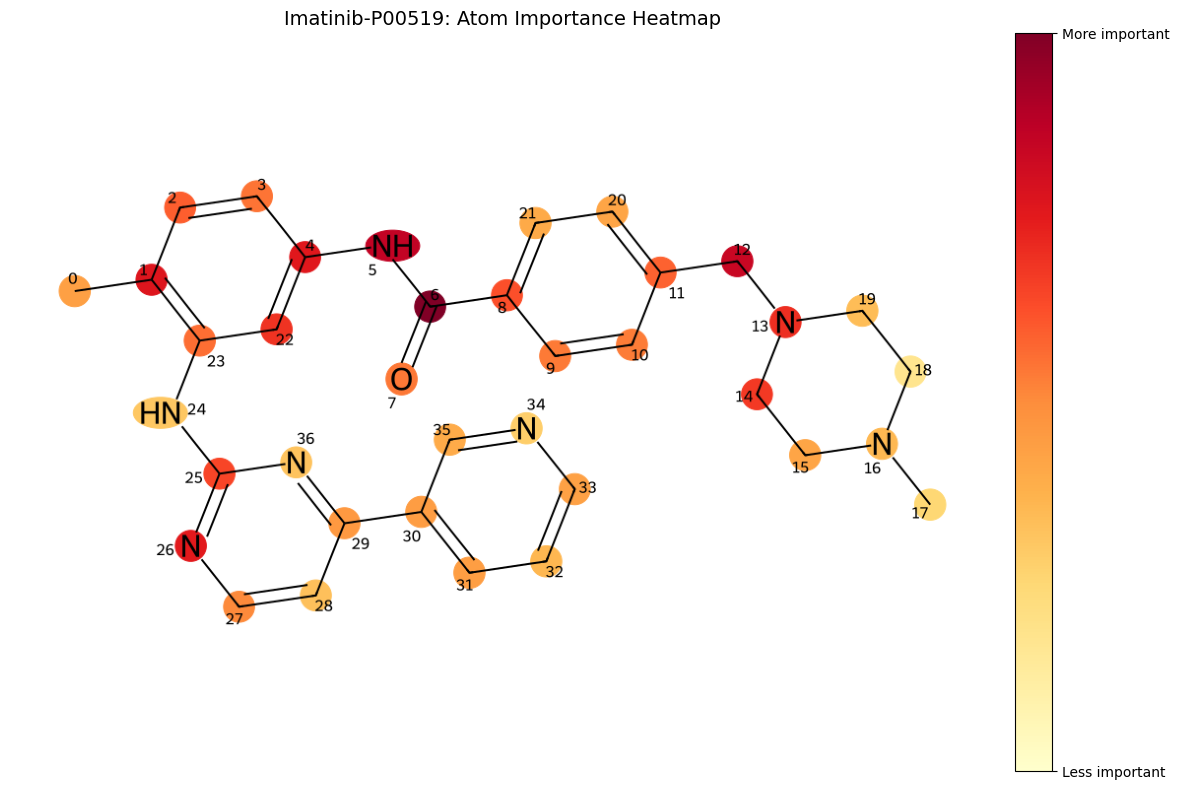


[Visualization 4] Drawing annotated structure...
[save] Annotated structure → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_annotated_normalized_with_z.png


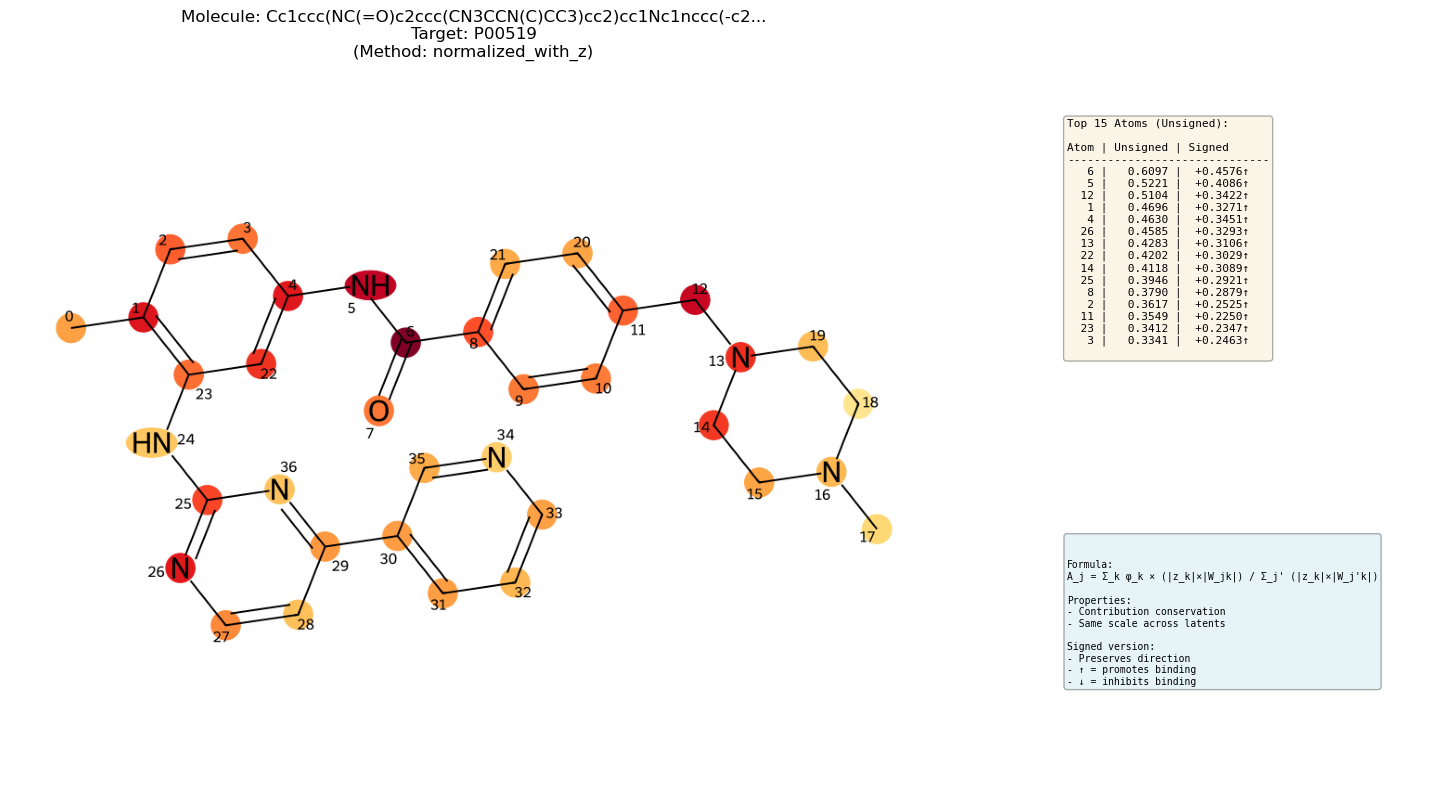

[save] Atom BitScore → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_atom_bitscore_normalized_with_z.csv

Top 10 atoms:


,atom_id,bitscore_unsigned,bitscore_signed,direction,num_latents,latents,atom_symbol
0,6,0.609744,0.457622,positive,5,"2,8,9,10,307",C
1,5,0.522133,0.408552,positive,5,"2,8,9,10,307",N
2,12,0.510386,0.342229,positive,5,"2,8,9,10,307",C
3,1,0.469623,0.327095,positive,5,"2,8,9,10,307",C
4,4,0.463044,0.345058,positive,5,"2,8,9,10,307",C
5,26,0.458478,0.329274,positive,5,"2,8,9,10,307",N
6,13,0.428326,0.310559,positive,5,"2,8,9,10,307",N
7,22,0.420168,0.302900,positive,5,"2,8,9,10,307",C
8,14,0.411816,0.308936,positive,5,"2,8,9,10,307",C
9,25,0.394617,0.292145,positive,5,"2,8,9,10,307",C



Top 5 positive atoms:


,atom_id,bitscore_unsigned,bitscore_signed,direction,num_latents,latents,atom_symbol
0,6,0.609744,0.457622,positive,5,"2,8,9,10,307",C
1,5,0.522133,0.408552,positive,5,"2,8,9,10,307",N
4,4,0.463044,0.345058,positive,5,"2,8,9,10,307",C
2,12,0.510386,0.342229,positive,5,"2,8,9,10,307",C
5,26,0.458478,0.329274,positive,5,"2,8,9,10,307",N



Top 5 negative atoms:


,atom_id,bitscore_unsigned,bitscore_signed,direction,num_latents,latents,atom_symbol



[Visualization 5] Diagnostic plots...
[save] Diagnostic plot → ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_diagnostic_normalized_with_z.png


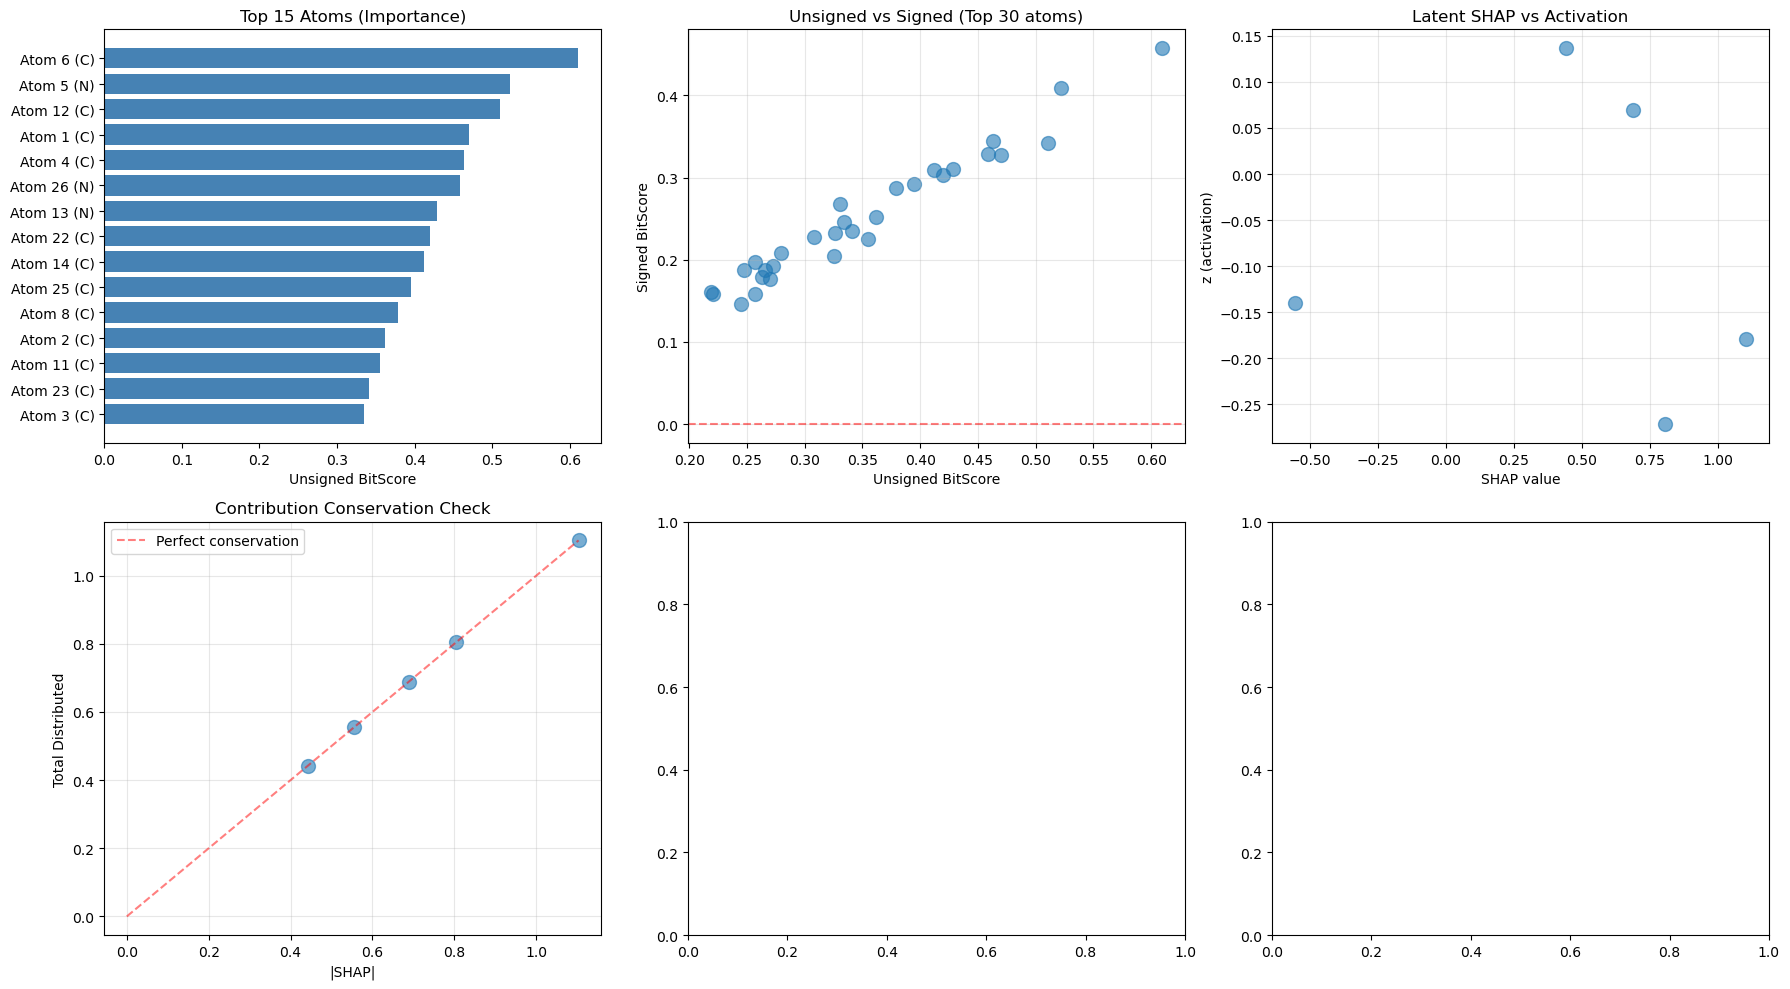


Molecule visualization complete!


In [7]:
# =========================
# 10) Molecular-structure highlight visualisation - improved version (normalised + signed)
# =========================

print("\n" + "="*60)
print("Molecule Structure Highlighting - Improved BitScore")
print(f"Method: {BITSCORE_METHOD}")
print(f"Signed version: {COMPUTE_SIGNED_BITSCORE}")
print("="*60)

from rdkit.Chem.Draw import rdMolDraw2D
from collections import defaultdict
from matplotlib import cm, colors
import matplotlib.pyplot as plt
from PIL import Image

# ---- Use the improved all_important_info_mol ----
vis_important_info = {}

for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
    vis_important_info[(atom_idx, rad_used, bit)] = {
        "bitscore_unsigned": info["bitscore_unsigned"],
        "bitscore_signed": info["bitscore_signed"] if COMPUTE_SIGNED_BITSCORE else None,
        "latent_contributions_unsigned": info["latent_contributions_unsigned"],
        "latent_contributions_signed": info["latent_contributions_signed"] if COMPUTE_SIGNED_BITSCORE else None,
        "top_3_latents": info["top_3_latents"],
        "num_contributing_latents": info["num_contributing_latents"]
    }

print(f"[info] Visualizing {len(vis_important_info)} substructures")

# ---- Combined highlight plot (unsigned values for colour)----
print("\n[Visualization] Drawing comprehensive heatmap (unsigned importance)...")

atom_bitscore_unsigned = defaultdict(float)
atom_bitscore_signed = defaultdict(float) if COMPUTE_SIGNED_BITSCORE else None
atom_latents = defaultdict(set)

for (atom_idx, rad_used, bit), info in vis_important_info.items():
    atoms, bonds = atoms_bonds_for_environment(mol, atom_idx, rad_used)
    bitscore_unsigned = info["bitscore_unsigned"]
    
    for a in atoms:
        atom_bitscore_unsigned[a] += bitscore_unsigned
        if COMPUTE_SIGNED_BITSCORE:
            atom_bitscore_signed[a] += info["bitscore_signed"]
        for lc in info["latent_contributions_unsigned"]:
            atom_latents[a].add(lc['latent'])

# Normalise (using unsigned values)
if atom_bitscore_unsigned:
    max_bitscore = max(atom_bitscore_unsigned.values())
    atom_bitscore_norm = {a: v/max_bitscore for a, v in atom_bitscore_unsigned.items()}
else:
    atom_bitscore_norm = {}

cmap = cm.get_cmap('YlOrRd')

highlight_atoms = list(atom_bitscore_norm.keys())
atom_colors = {}
for a in highlight_atoms:
    intensity = atom_bitscore_norm[a]
    color = cmap(intensity)
    atom_colors[a] = tuple(color[:3])

drawer = rdMolDraw2D.MolDraw2DCairo(1000, 750)
drawer.drawOptions().addAtomIndices = True
drawer.drawOptions().bondLineWidth = 2

rdMolDraw2D.PrepareAndDrawMolecule(
    drawer, mol,
    highlightAtoms=highlight_atoms,
    highlightAtomColors=atom_colors,
    # legend=f"{kinase_name}: {len(highlight_atoms)} atoms\n({BITSCORE_METHOD})"
)
drawer.FinishDrawing()

comprehensive_img = os.path.join(outdir, f"mol_comprehensive_heatmap_{BITSCORE_METHOD}.png")
with open(comprehensive_img, "wb") as f:
    f.write(drawer.GetDrawingText())
print(f"[save] Comprehensive heatmap → {comprehensive_img}")


# ---- Insert colour scale ----

img = Image.open(comprehensive_img)

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)
ax.axis('off')
ax.set_title(f"{drug_name}-{kinase_name}: Atom Importance Heatmap", fontsize=14)

# Important: use the cmap defined earlier
norm = colors.Normalize(vmin=0, vmax=1)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
# cbar.set_label("Atom importance (normalized BitScore)", fontsize=11)

cbar.set_ticks([0,1.0])
cbar.set_ticklabels([
    "Less important",
    "More important"
])

plt.tight_layout()

heatmap_with_bar = os.path.join(outdir, f"mol_comprehensive_heatmap_with_colorbar_{BITSCORE_METHOD}.png")
plt.savefig(heatmap_with_bar, dpi=200, bbox_inches='tight')
print(f"[save] Heatmap with colorbar → {heatmap_with_bar}")
plt.show()

# ---- Method 4: detailed plot with annotations ----
print("\n[Visualization 4] Drawing annotated structure...")

fig, (ax_mol, ax_legend) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [3, 1]})

img = Image.open(comprehensive_img)
ax_mol.imshow(img)
ax_mol.axis('off')
ax_mol.set_title(f"Molecule: {drug_smiles[:50]}...\nTarget: {kinase_name}\n(Method: {BITSCORE_METHOD})", 
                 fontsize=12, pad=20)

ax_legend.axis('off')

atom_imp_sorted = sorted(atom_bitscore_unsigned.items(), key=lambda x: x[1], reverse=True)[:15]
legend_text = "Top 15 Atoms (Unsigned):\n\n"
legend_text += "Atom | Unsigned"
if COMPUTE_SIGNED_BITSCORE:
    legend_text += " | Signed"
legend_text += "\n" + "-" * 30 + "\n"

for atom_id, unsigned_score in atom_imp_sorted:
    line = f"{atom_id:4d} | {unsigned_score:8.4f}"
    if COMPUTE_SIGNED_BITSCORE:
        signed_score = atom_bitscore_signed.get(atom_id, 0)
        direction = "↑" if signed_score > 0 else "↓"
        line += f" | {signed_score:+8.4f}{direction}"
    legend_text += line + "\n"

ax_legend.text(0.05, 0.95, legend_text, 
               transform=ax_legend.transAxes,
               fontsize=8,
               verticalalignment='top',
               fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

# Formula explanation
if BITSCORE_METHOD == "normalized_with_z":
    formula = "A_j = Σ_k φ_k × (|z_k|×|W_jk|) / Σ_j' (|z_k|×|W_j'k|)"
elif BITSCORE_METHOD == "normalized_no_z":
    formula = "A_j = Σ_k φ_k × |W_jk| / Σ_j' |W_j'k|"
else:
    formula = "A_j = b_j × Σ_k |φ_k| × |z_k| × |W_jk|"

formula_text = f"\n\nFormula:\n{formula}\n\n"
formula_text += "Properties:\n"
formula_text += "- Contribution conservation\n"
formula_text += "- Same scale across latents\n"
if COMPUTE_SIGNED_BITSCORE:
    formula_text += "\nSigned version:\n"
    formula_text += "- Preserves direction\n"
    formula_text += "- ↑ = promotes binding\n"
    formula_text += "- ↓ = inhibits binding"

ax_legend.text(0.05, 0.35, formula_text,
               transform=ax_legend.transAxes,
               fontsize=7,
               verticalalignment='top',
               fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))

plt.tight_layout()
annotated_img = os.path.join(outdir, f"mol_annotated_{BITSCORE_METHOD}.png")
plt.savefig(annotated_img, dpi=150, bbox_inches='tight')
print(f"[save] Annotated structure → {annotated_img}")
plt.show()

# ---- Save atom table ----
atom_imp_df = pd.DataFrame([
    {
        "atom_id": atom_id,
        "bitscore_unsigned": unsigned_score,
        "bitscore_signed": atom_bitscore_signed.get(atom_id, 0) if COMPUTE_SIGNED_BITSCORE else None,
        "direction": "positive" if (COMPUTE_SIGNED_BITSCORE and atom_bitscore_signed.get(atom_id, 0) > 0) else "negative" if COMPUTE_SIGNED_BITSCORE else None,
        "num_latents": len(atom_latents[atom_id]),
        "latents": ",".join(map(str, sorted(atom_latents[atom_id]))),
        "atom_symbol": mol.GetAtomWithIdx(atom_id).GetSymbol()
    }
    for atom_id, unsigned_score in sorted(atom_bitscore_unsigned.items(), key=lambda x: x[1], reverse=True)
])

atom_csv = os.path.join(outdir, f"mol_atom_bitscore_{BITSCORE_METHOD}.csv")
atom_imp_df.to_csv(atom_csv, index=False)
print(f"[save] Atom BitScore → {atom_csv}")

print("\nTop 10 atoms:")
display(atom_imp_df.head(10))

if COMPUTE_SIGNED_BITSCORE:
    print("\nTop 5 positive atoms:")
    df_pos = atom_imp_df[atom_imp_df["bitscore_signed"] > 0].sort_values("bitscore_signed", ascending=False)
    display(df_pos.head(5))
    
    print("\nTop 5 negative atoms:")
    df_neg = atom_imp_df[atom_imp_df["bitscore_signed"] < 0].sort_values("bitscore_signed", ascending=True)
    display(df_neg.head(5))

# ---- Method 5: diagnostic plots ----
print("\n[Visualization 5] Diagnostic plots...")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Subplot 1: top atoms (unsigned)
top_atoms = atom_imp_df.head(15)
axes[0, 0].barh(range(len(top_atoms)), top_atoms['bitscore_unsigned'].values, color='steelblue')
axes[0, 0].set_yticks(range(len(top_atoms)))
axes[0, 0].set_yticklabels([f"Atom {a} ({s})" 
                            for a, s in zip(top_atoms['atom_id'].values, 
                                          top_atoms['atom_symbol'].values)])
axes[0, 0].set_xlabel("Unsigned BitScore")
axes[0, 0].set_title("Top 15 Atoms (Importance)")
axes[0, 0].invert_yaxis()

# Subplot 2: signed vs unsigned (if available)
if COMPUTE_SIGNED_BITSCORE:
    unsigned_vals = atom_imp_df.head(30)['bitscore_unsigned'].values
    signed_vals = atom_imp_df.head(30)['bitscore_signed'].values
    
    axes[0, 1].scatter(unsigned_vals, signed_vals, alpha=0.6, s=100)
    axes[0, 1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[0, 1].set_xlabel("Unsigned BitScore")
    axes[0, 1].set_ylabel("Signed BitScore")
    axes[0, 1].set_title("Unsigned vs Signed (Top 30 atoms)")
    axes[0, 1].grid(alpha=0.3)
else:
    axes[0, 1].text(0.5, 0.5, "Signed version disabled", 
                   ha='center', va='center', transform=axes[0, 1].transAxes)
    axes[0, 1].axis('off')

# Subplot 3: latent SHAP vs z
latent_shap = [mol_shap_values[lx] for lx in important_mol_latents]
latent_z = [mol_z_values[lx] for lx in important_mol_latents]

axes[0, 2].scatter(latent_shap, latent_z, s=100, alpha=0.6)
axes[0, 2].set_xlabel("SHAP value")
axes[0, 2].set_ylabel("z (activation)")
axes[0, 2].set_title("Latent SHAP vs Activation")
axes[0, 2].grid(alpha=0.3)

# Subplot 4: latent contribution validation (normalised method)
if BITSCORE_METHOD.startswith("normalized"):
    latent_contributions_check = []
    
    for lx in important_mol_latents:
        if lx < mol_Wdec_selected.shape[1]:
            s_k = mol_shap_values[lx]
            
            # Calculate the total attributed contribution of this latent
            total_contrib = 0
            for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
                for lc in info["latent_contributions_unsigned"]:
                    if lc['latent'] == lx:
                        total_contrib += lc['contribution']
            
            latent_contributions_check.append({
                'latent': lx,
                'shap_abs': np.abs(s_k),
                'distributed': total_contrib
            })
    
    df_check = pd.DataFrame(latent_contributions_check)
    
    axes[1, 0].scatter(df_check['shap_abs'], df_check['distributed'], s=100, alpha=0.6)
    axes[1, 0].plot([0, df_check['shap_abs'].max()], [0, df_check['shap_abs'].max()], 
                   'r--', alpha=0.5, label='Perfect conservation')
    axes[1, 0].set_xlabel("|SHAP|")
    axes[1, 0].set_ylabel("Total Distributed")
    axes[1, 0].set_title("Contribution Conservation Check")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, "Conservation check\nonly for normalized methods", 
                   ha='center', va='center', transform=axes[1, 0].transAxes)
    axes[1, 0].axis('off')


plt.tight_layout()
diagnostic_img = os.path.join(outdir, f"mol_diagnostic_{BITSCORE_METHOD}.png")
plt.savefig(diagnostic_img, dpi=150, bbox_inches='tight')
print(f"[save] Diagnostic plot → {diagnostic_img}")
plt.show()

print("\n" + "="*60)
print("Molecule visualization complete!")
print("="*60)


Molecule Structure Highlighting - POSITIVE signed BitScore
Method: normalized_with_z
Signed version: True
[info] Visualizing 65 substructures

[Visualization] Drawing comprehensive heatmap (positive contributors)...
[save] Comprehensive heatmap (positive) -> ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_comprehensive_heatmap_normalized_with_z_pos.png


/tmp/ipykernel_2926/2271272236.py:70: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlOrRd')   # SAME sequential colormap as Section 10


[save] Heatmap with colorbar (positive) -> ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_comprehensive_heatmap_with_colorbar_normalized_with_z_pos.png


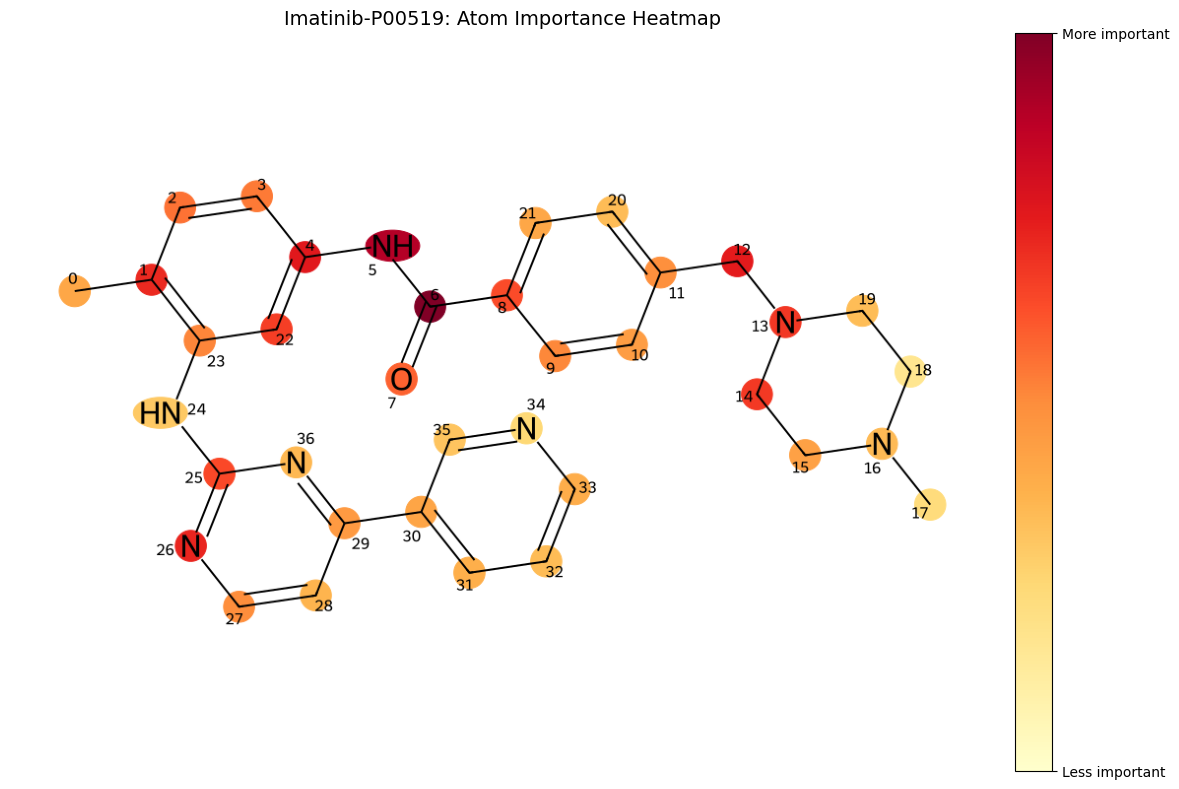


[Visualization 4] Drawing annotated structure...
[save] Annotated structure (positive) -> ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_annotated_normalized_with_z_pos.png


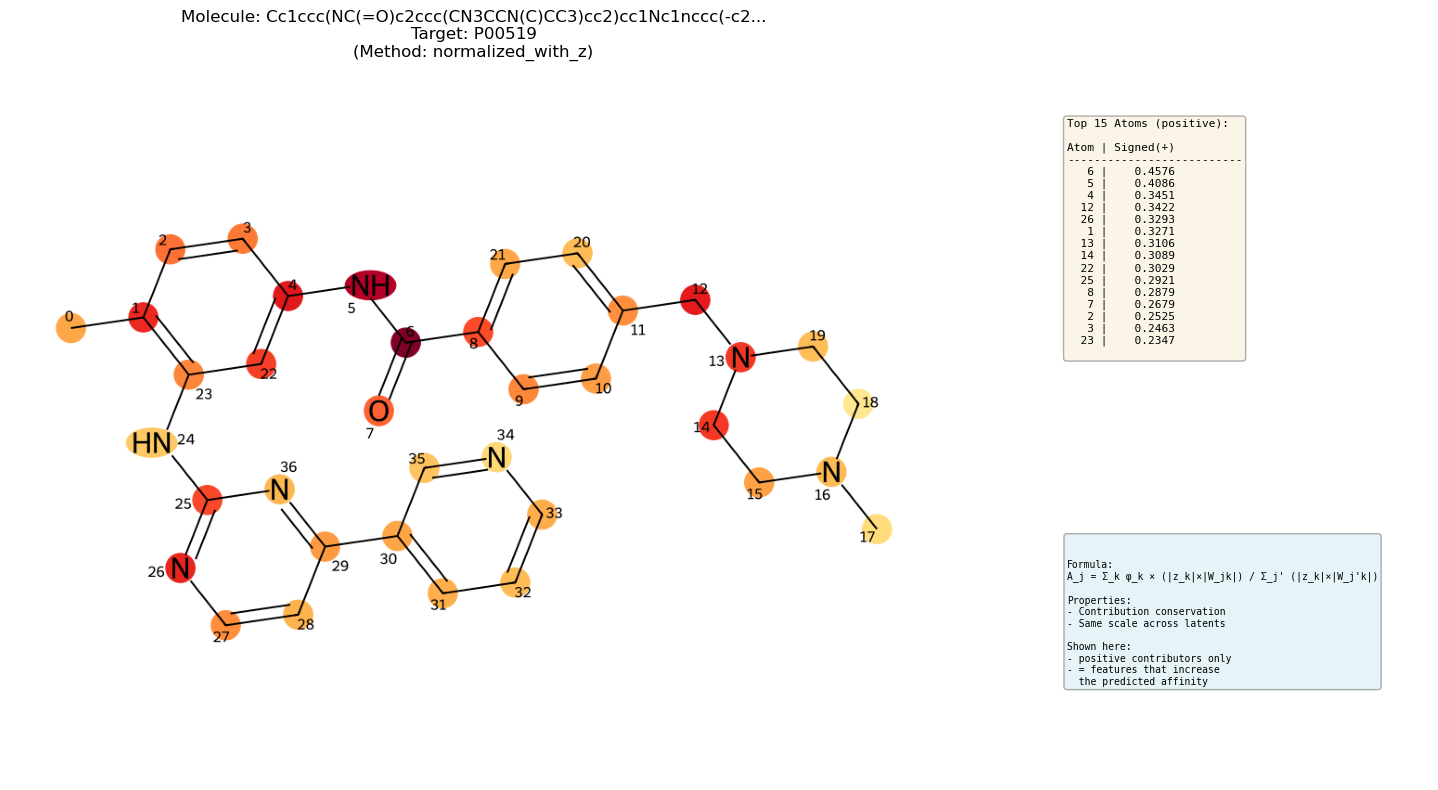

[save] Atom BitScore (signed, sorted) -> ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_atom_bitscore_normalized_with_z_pos.csv

Top 10 positive-contributing atoms:


,atom_id,bitscore_signed,bitscore_unsigned,direction,num_latents,latents,atom_symbol
0,6,0.457622,0.609744,positive,5,"2,8,9,10,307",C
1,5,0.408552,0.522133,positive,5,"2,8,9,10,307",N
2,4,0.345058,0.463044,positive,5,"2,8,9,10,307",C
3,12,0.342229,0.510386,positive,5,"2,8,9,10,307",C
4,26,0.329274,0.458478,positive,5,"2,8,9,10,307",N
5,1,0.327095,0.469623,positive,5,"2,8,9,10,307",C
6,13,0.310559,0.428326,positive,5,"2,8,9,10,307",N
7,14,0.308936,0.411816,positive,5,"2,8,9,10,307",C
8,22,0.302900,0.420168,positive,5,"2,8,9,10,307",C
9,25,0.292145,0.394617,positive,5,"2,8,9,10,307",C



[Visualization 5] Diagnostic plots...
[save] Diagnostic plot (positive) -> ./Linear_SAE_xgb_shap_P00519_Imatinib/mol_diagnostic_normalized_with_z_pos.png


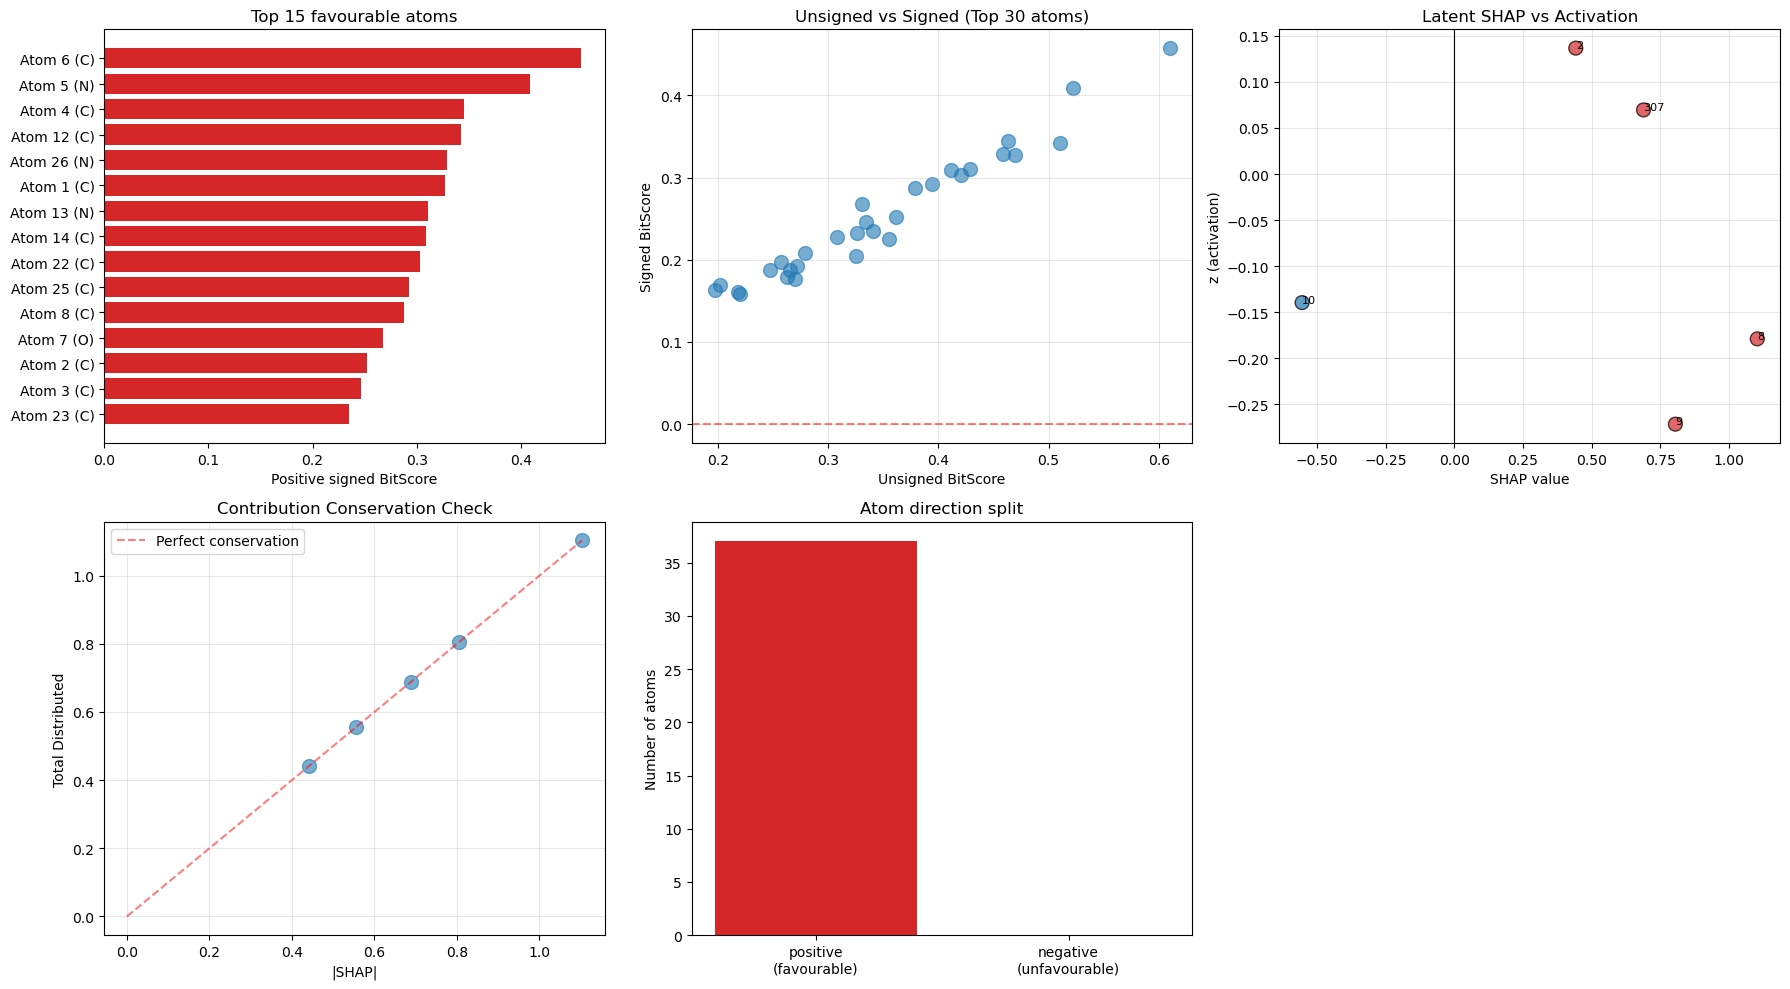


Positive-contributor molecule visualization complete!


In [8]:
# =========================
# 10-2) Molecular-structure highlight visualisation - POSITIVE signed BitScore
# (identical figure format to Section 10; shows ONLY binding-favourable features)
# =========================

print("\n" + "="*60)
print("Molecule Structure Highlighting - POSITIVE signed BitScore")
print(f"Method: {BITSCORE_METHOD}")
print(f"Signed version: {COMPUTE_SIGNED_BITSCORE}")
print("="*60)

from rdkit.Chem.Draw import rdMolDraw2D
from collections import defaultdict
from matplotlib import cm, colors
import matplotlib.pyplot as plt
from PIL import Image

# ---- guard: positive signed needs the signed scores ----
if not COMPUTE_SIGNED_BITSCORE:
    raise RuntimeError(
        "Positive signed visualisation needs COMPUTE_SIGNED_BITSCORE=True. "
        "Set it True and re-run Sections 6-7 first."
    )

# ---- Use the improved all_important_info_mol ----
vis_important_info = {}

for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
    vis_important_info[(atom_idx, rad_used, bit)] = {
        "bitscore_unsigned": info["bitscore_unsigned"],
        "bitscore_signed": info["bitscore_signed"],
        "latent_contributions_unsigned": info["latent_contributions_unsigned"],
        "latent_contributions_signed": info["latent_contributions_signed"],
        "top_3_latents": info["top_3_latents"],
        "num_contributing_latents": info["num_contributing_latents"]
    }

print(f"[info] Visualizing {len(vis_important_info)} substructures")

# ---- Combined highlight plot (POSITIVE signed values for colour, same format) ----
print("\n[Visualization] Drawing comprehensive heatmap (positive contributors)...")

atom_bitscore_unsigned = defaultdict(float)
atom_bitscore_signed = defaultdict(float)
atom_latents = defaultdict(set)

for (atom_idx, rad_used, bit), info in vis_important_info.items():
    atoms, bonds = atoms_bonds_for_environment(mol, atom_idx, rad_used)
    bitscore_unsigned = info["bitscore_unsigned"]

    for a in atoms:
        atom_bitscore_unsigned[a] += bitscore_unsigned
        atom_bitscore_signed[a] += info["bitscore_signed"]
        for lc in info["latent_contributions_unsigned"]:
            atom_latents[a].add(lc['latent'])

# --- positive part of the signed BitScore: features that contribute TO binding ---
# Net per-atom positivity. To instead keep "any positively-contributing bit", clip at the
# bit level before aggregation: use max(info["bitscore_signed"], 0) inside the loop above.
atom_bitscore_pos = {a: v for a, v in atom_bitscore_signed.items() if v > 0}

# Normalise (using positive signed values) - format unchanged
if atom_bitscore_pos:
    max_bitscore = max(atom_bitscore_pos.values())
    atom_bitscore_norm = {a: v / max_bitscore for a, v in atom_bitscore_pos.items()}
else:
    atom_bitscore_norm = {}
    print("[WARN] No atoms with positive signed BitScore under the current latents.")

cmap = cm.get_cmap('YlOrRd')   # SAME sequential colormap as Section 10

highlight_atoms = list(atom_bitscore_norm.keys())
atom_colors = {}
for a in highlight_atoms:
    intensity = atom_bitscore_norm[a]
    color = cmap(intensity)
    atom_colors[a] = tuple(color[:3])

drawer = rdMolDraw2D.MolDraw2DCairo(1000, 750)
drawer.drawOptions().addAtomIndices = True
drawer.drawOptions().bondLineWidth = 2

rdMolDraw2D.PrepareAndDrawMolecule(
    drawer, mol,
    highlightAtoms=highlight_atoms,
    highlightAtomColors=atom_colors,
)
drawer.FinishDrawing()

comprehensive_img = os.path.join(outdir, f"mol_comprehensive_heatmap_{BITSCORE_METHOD}_pos.png")
with open(comprehensive_img, "wb") as f:
    f.write(drawer.GetDrawingText())
print(f"[save] Comprehensive heatmap (positive) -> {comprehensive_img}")


# ---- Insert colour scale (identical to Section 10) ----

img = Image.open(comprehensive_img)

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)
ax.axis('off')
ax.set_title(f"{drug_name}-{kinase_name}: Atom Importance Heatmap", fontsize=14)

norm = colors.Normalize(vmin=0, vmax=1)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
cbar.set_ticks([0, 1.0])
cbar.set_ticklabels([
    "Less important",
    "More important"
])
# (For the manuscript you may relabel these to
#  "Weaker contribution" / "Stronger contribution" - text only, format unchanged.)

plt.tight_layout()

heatmap_with_bar = os.path.join(
    outdir, f"mol_comprehensive_heatmap_with_colorbar_{BITSCORE_METHOD}_pos.png")
plt.savefig(heatmap_with_bar, dpi=200, bbox_inches='tight')
print(f"[save] Heatmap with colorbar (positive) -> {heatmap_with_bar}")
plt.show()

# ---- Method 4: detailed plot with annotations ----
print("\n[Visualization 4] Drawing annotated structure...")

fig, (ax_mol, ax_legend) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [3, 1]})

img = Image.open(comprehensive_img)
ax_mol.imshow(img)
ax_mol.axis('off')
ax_mol.set_title(f"Molecule: {drug_smiles[:50]}...\nTarget: {kinase_name}\n(Method: {BITSCORE_METHOD})",
                 fontsize=12, pad=20)

ax_legend.axis('off')

# top-15 positive contributors
atom_imp_sorted = sorted(atom_bitscore_pos.items(), key=lambda x: x[1], reverse=True)[:15]
legend_text = "Top 15 Atoms (positive):\n\n"
legend_text += "Atom | Signed(+)\n"
legend_text += "-" * 26 + "\n"

for atom_id, signed_score in atom_imp_sorted:
    legend_text += f"{atom_id:4d} | {signed_score:9.4f}\n"

ax_legend.text(0.05, 0.95, legend_text,
               transform=ax_legend.transAxes,
               fontsize=8,
               verticalalignment='top',
               fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

# Formula explanation
if BITSCORE_METHOD == "normalized_with_z":
    formula = "A_j = Σ_k φ_k × (|z_k|×|W_jk|) / Σ_j' (|z_k|×|W_j'k|)"
elif BITSCORE_METHOD == "normalized_no_z":
    formula = "A_j = Σ_k φ_k × |W_jk| / Σ_j' |W_j'k|"
else:
    formula = "A_j = Σ_k φ_k × z_k × W_jk"

formula_text = f"\n\nFormula:\n{formula}\n\n"
formula_text += "Properties:\n"
formula_text += "- Contribution conservation\n"
formula_text += "- Same scale across latents\n"
formula_text += "\nShown here:\n"
formula_text += "- positive contributors only\n"
formula_text += "- = features that increase\n"
formula_text += "  the predicted affinity"

ax_legend.text(0.05, 0.35, formula_text,
               transform=ax_legend.transAxes,
               fontsize=7,
               verticalalignment='top',
               fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))

plt.tight_layout()
annotated_img = os.path.join(outdir, f"mol_annotated_{BITSCORE_METHOD}_pos.png")
plt.savefig(annotated_img, dpi=150, bbox_inches='tight')
print(f"[save] Annotated structure (positive) -> {annotated_img}")
plt.show()

# ---- Save atom table (all atoms, signed + direction; sorted by signed desc) ----
atom_imp_df = pd.DataFrame([
    {
        "atom_id": atom_id,
        "bitscore_signed": signed_score,
        "bitscore_unsigned": atom_bitscore_unsigned.get(atom_id, 0.0),
        "direction": "positive" if signed_score > 0 else "negative",
        "num_latents": len(atom_latents[atom_id]),
        "latents": ",".join(map(str, sorted(atom_latents[atom_id]))),
        "atom_symbol": mol.GetAtomWithIdx(atom_id).GetSymbol()
    }
    for atom_id, signed_score in sorted(
        atom_bitscore_signed.items(), key=lambda x: x[1], reverse=True)
])

atom_csv = os.path.join(outdir, f"mol_atom_bitscore_{BITSCORE_METHOD}_pos.csv")
atom_imp_df.to_csv(atom_csv, index=False)
print(f"[save] Atom BitScore (signed, sorted) -> {atom_csv}")

print("\nTop 10 positive-contributing atoms:")
display(atom_imp_df[atom_imp_df["bitscore_signed"] > 0].head(10))

# ---- Method 5: diagnostic plots ----
print("\n[Visualization 5] Diagnostic plots...")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Subplot 1: top positive atoms
df_pos_only = atom_imp_df[atom_imp_df["bitscore_signed"] > 0].head(15)
axes[0, 0].barh(range(len(df_pos_only)), df_pos_only['bitscore_signed'].values, color='#d62728')
axes[0, 0].set_yticks(range(len(df_pos_only)))
axes[0, 0].set_yticklabels([f"Atom {a} ({s})"
                            for a, s in zip(df_pos_only['atom_id'].values,
                                            df_pos_only['atom_symbol'].values)])
axes[0, 0].set_xlabel("Positive signed BitScore")
axes[0, 0].set_title("Top 15 favourable atoms")
axes[0, 0].invert_yaxis()

# Subplot 2: signed vs unsigned (top 30 by |signed|)
top30 = atom_imp_df.reindex(atom_imp_df['bitscore_signed'].abs().sort_values(ascending=False).index).head(30)
axes[0, 1].scatter(top30['bitscore_unsigned'].values, top30['bitscore_signed'].values, alpha=0.6, s=100)
axes[0, 1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel("Unsigned BitScore")
axes[0, 1].set_ylabel("Signed BitScore")
axes[0, 1].set_title("Unsigned vs Signed (Top 30 atoms)")
axes[0, 1].grid(alpha=0.3)

# Subplot 3: latent SHAP vs z, coloured by sign
latent_shap = [mol_shap_values[lx] for lx in important_mol_latents]
latent_z = [mol_z_values[lx] for lx in important_mol_latents]
latent_c = ["#d62728" if s > 0 else "#1f77b4" for s in latent_shap]
axes[0, 2].scatter(latent_shap, latent_z, c=latent_c, s=100, alpha=0.7, edgecolor='k')
for lx, s, z in zip(important_mol_latents, latent_shap, latent_z):
    axes[0, 2].annotate(str(lx), (s, z), fontsize=8)
axes[0, 2].axvline(0, color='k', lw=0.8)
axes[0, 2].set_xlabel("SHAP value")
axes[0, 2].set_ylabel("z (activation)")
axes[0, 2].set_title("Latent SHAP vs Activation")
axes[0, 2].grid(alpha=0.3)

# Subplot 4: latent contribution validation (normalised method)
if BITSCORE_METHOD.startswith("normalized"):
    latent_contributions_check = []

    for lx in important_mol_latents:
        if lx < mol_Wdec_selected.shape[1]:
            s_k = mol_shap_values[lx]

            total_contrib = 0
            for (atom_idx, rad_used, bit), info in all_important_info_mol.items():
                for lc in info["latent_contributions_unsigned"]:
                    if lc['latent'] == lx:
                        total_contrib += lc['contribution']

            latent_contributions_check.append({
                'latent': lx,
                'shap_abs': np.abs(s_k),
                'distributed': total_contrib
            })

    df_check = pd.DataFrame(latent_contributions_check)

    axes[1, 0].scatter(df_check['shap_abs'], df_check['distributed'], s=100, alpha=0.6)
    axes[1, 0].plot([0, df_check['shap_abs'].max()], [0, df_check['shap_abs'].max()],
                    'r--', alpha=0.5, label='Perfect conservation')
    axes[1, 0].set_xlabel("|SHAP|")
    axes[1, 0].set_ylabel("Total Distributed")
    axes[1, 0].set_title("Contribution Conservation Check")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, "Conservation check\nonly for normalized methods",
                    ha='center', va='center', transform=axes[1, 0].transAxes)
    axes[1, 0].axis('off')

# Subplot 5: positive vs negative atom count
n_pos = int((atom_imp_df["bitscore_signed"] > 0).sum())
n_neg = int((atom_imp_df["bitscore_signed"] < 0).sum())
axes[1, 1].bar(["positive\n(favourable)", "negative\n(unfavourable)"], [n_pos, n_neg],
               color=["#d62728", "#1f77b4"])
axes[1, 1].set_ylabel("Number of atoms")
axes[1, 1].set_title("Atom direction split")

# Subplot 6: empty
axes[1, 2].axis('off')

plt.tight_layout()
diagnostic_img = os.path.join(outdir, f"mol_diagnostic_{BITSCORE_METHOD}_pos.png")
plt.savefig(diagnostic_img, dpi=150, bbox_inches='tight')
print(f"[save] Diagnostic plot (positive) -> {diagnostic_img}")
plt.show()

print("\n" + "="*60)
print("Positive-contributor molecule visualization complete!")
print("="*60)


Protein Inverse Mapping - MCA BitScore
Method: normalized_with_z
Signed version: True
[info] Loaded MCA category loadings: 200 components
[info] MCA bit categories with loadings: 1823 / 1955
[WARN] 132 KLIFS bit categories were absent from the fitted MCA dummy matrix.
       Example missing categories: ['res03_sidechain_Imino', 'res03_sidechain_Acidic_sc', 'res03_functional_Acidic_fn', 'res03_size_Tiny', 'res04_sidechain_Aromatic', 'res06_sidechain_Aromatic', 'res06_sidechain_Imino', 'res08_sidechain_Imino', 'res11_sidechain_Acidic_sc', 'res11_functional_Acidic_fn']
[info] Protein MCA coordinate range: [-0.2640, 0.5453]
[info] Protein onehot shape: (1955,)
[info] Active bits: 425
[info] Using normalized attribution with z_k (protein)

[info] Unsigned BitScore range: [0.000000, 0.025419]
[info] Bits with unsigned BitScore > 0: 425
[info] Signed BitScore range: [-0.004441, 0.023185]
[info] Signed: 379 positive, 46 negative

[save] Residue BitScore → ./Linear_SAE_xgb_shap_P00519_Imatinib

,residue_position,bitscore_unsigned,n_active_properties,active_properties,top_property,top_property_score,top_category,top_category_score,Sidechain_unsigned,Tertiary_Structure_unsigned,...,Size_active,top_3_components,num_contributing_components,bitscore_signed,direction,Sidechain_signed,Tertiary_Structure_signed,Functional_Property_signed,Secondary_Structure_signed,Size_signed
71,72,0.094195,5,"Aliphatic,Intermediate,Hydrophobic,alpha_helix...",Aliphatic,0.025419,Sidechain,0.025419,0.025419,0.017744,...,Tiny,"3(0.0588),2(0.0307),33(0.0032)",5,0.086373,positive,0.023185,0.016684,0.023185,0.000133,0.023185
44,45,0.061892,5,"Hydroxyl,Intermediate,Polar,beta_strand,Small",beta_strand,0.014709,Secondary_Structure,0.014709,0.012300,0.012413,...,Small,"3(0.0311),51(0.0181),33(0.0117)",5,0.060931,positive,0.012300,0.012402,0.011426,0.013883,0.010921
73,74,0.054398,5,"Basic,Exposed,Basic_func,alpha_helix,Very_Large",Very_Large,0.016883,Size,0.016883,0.016221,0.000786,...,Very_Large,"3(0.0439),2(0.0066),51(0.0029)",5,0.050438,positive,0.015643,0.000604,0.016501,0.001260,0.016431
75,76,0.044213,5,"Sulfur,Intermediate,Polar,beta_strand,Small",Sulfur,0.013339,Sidechain,0.013339,0.013339,0.012141,...,Small,"3(0.0234),33(0.0120),51(0.0041)",5,0.018489,positive,0.004236,0.004952,0.005265,0.000602,0.003433
38,39,0.043939,5,"Aliphatic,Buried,Hydrophobic,alpha_helix,Medium",Buried,0.012618,Tertiary_Structure,0.012618,0.008486,0.012618,...,Medium,"51(0.0325),3(0.0045),33(0.0034)",5,0.036688,positive,0.008174,0.009414,0.007508,0.001843,0.009748
20,21,0.037621,5,"Aromatic,Buried,Hydrophobic,beta_strand,Very_L...",Aromatic,0.013749,Sidechain,0.013749,0.013749,0.003511,...,Very_Large,"3(0.0237),2(0.0074),51(0.0040)",5,0.034150,positive,0.012376,0.003039,0.002449,0.004152,0.012133
72,73,0.036296,5,"Aliphatic,Intermediate,Hydrophobic,alpha_helix...",Tiny,0.017030,Size,0.017030,0.008783,0.000842,...,Tiny,"3(0.0182),2(0.0081),167(0.0062)",5,0.030515,positive,0.005637,0.000735,0.000365,0.008070,0.015707
39,40,0.036045,5,"Aliphatic,Intermediate,Polar,Coil,Tiny",Tiny,0.013461,Size,0.013461,0.012107,0.003091,...,Tiny,"3(0.0279),2(0.0051),51(0.0019)",5,0.030124,positive,0.011212,0.002657,0.000203,0.003918,0.012134
4,5,0.035899,5,"Aliphatic,Intermediate,Polar,Coil,Tiny",Tiny,0.015403,Size,0.015403,0.004924,0.007908,...,Tiny,"167(0.0130),33(0.0098),3(0.0065)",5,0.008179,positive,0.000027,0.003506,0.003328,0.000845,0.000473
17,18,0.029930,5,"Hydroxyl,Intermediate,Polar,beta_strand,Small",Hydroxyl,0.012456,Sidechain,0.012456,0.012456,0.007819,...,Small,"3(0.0162),2(0.0064),51(0.0053)",5,0.017169,positive,0.011291,0.002653,0.002154,0.000633,0.000437



Top 10 positive residues:


,residue_position,bitscore_unsigned,n_active_properties,active_properties,top_property,top_property_score,top_category,top_category_score,Sidechain_unsigned,Tertiary_Structure_unsigned,...,Size_active,top_3_components,num_contributing_components,bitscore_signed,direction,Sidechain_signed,Tertiary_Structure_signed,Functional_Property_signed,Secondary_Structure_signed,Size_signed
71,72,0.094195,5,"Aliphatic,Intermediate,Hydrophobic,alpha_helix...",Aliphatic,0.025419,Sidechain,0.025419,0.025419,0.017744,...,Tiny,"3(0.0588),2(0.0307),33(0.0032)",5,0.086373,positive,0.023185,0.016684,0.023185,0.000133,0.023185
44,45,0.061892,5,"Hydroxyl,Intermediate,Polar,beta_strand,Small",beta_strand,0.014709,Secondary_Structure,0.014709,0.012300,0.012413,...,Small,"3(0.0311),51(0.0181),33(0.0117)",5,0.060931,positive,0.012300,0.012402,0.011426,0.013883,0.010921
73,74,0.054398,5,"Basic,Exposed,Basic_func,alpha_helix,Very_Large",Very_Large,0.016883,Size,0.016883,0.016221,0.000786,...,Very_Large,"3(0.0439),2(0.0066),51(0.0029)",5,0.050438,positive,0.015643,0.000604,0.016501,0.001260,0.016431
38,39,0.043939,5,"Aliphatic,Buried,Hydrophobic,alpha_helix,Medium",Buried,0.012618,Tertiary_Structure,0.012618,0.008486,0.012618,...,Medium,"51(0.0325),3(0.0045),33(0.0034)",5,0.036688,positive,0.008174,0.009414,0.007508,0.001843,0.009748
20,21,0.037621,5,"Aromatic,Buried,Hydrophobic,beta_strand,Very_L...",Aromatic,0.013749,Sidechain,0.013749,0.013749,0.003511,...,Very_Large,"3(0.0237),2(0.0074),51(0.0040)",5,0.034150,positive,0.012376,0.003039,0.002449,0.004152,0.012133
72,73,0.036296,5,"Aliphatic,Intermediate,Hydrophobic,alpha_helix...",Tiny,0.017030,Size,0.017030,0.008783,0.000842,...,Tiny,"3(0.0182),2(0.0081),167(0.0062)",5,0.030515,positive,0.005637,0.000735,0.000365,0.008070,0.015707
39,40,0.036045,5,"Aliphatic,Intermediate,Polar,Coil,Tiny",Tiny,0.013461,Size,0.013461,0.012107,0.003091,...,Tiny,"3(0.0279),2(0.0051),51(0.0019)",5,0.030124,positive,0.011212,0.002657,0.000203,0.003918,0.012134
24,25,0.026805,5,"Aliphatic,Intermediate,Hydrophobic,alpha_helix...",Tiny,0.012709,Size,0.012709,0.002702,0.008287,...,Tiny,"3(0.0184),2(0.0055),167(0.0018)",5,0.023195,positive,0.002444,0.006844,0.002247,0.000150,0.011509
55,56,0.026871,5,"Aromatic,Intermediate,Polar,beta_strand,Very_L...",Aromatic,0.008771,Sidechain,0.008771,0.008771,0.004301,...,Very_Large,"3(0.0151),2(0.0058),167(0.0034)",5,0.021446,positive,0.007775,0.001791,0.001267,0.004920,0.005692
61,62,0.029527,5,"Acidic,Exposed,Acidic_func,alpha_helix,Large",Acidic,0.012142,Sidechain,0.012142,0.012142,0.001938,...,Large,"3(0.0141),2(0.0096),33(0.0028)",5,0.020336,positive,0.011620,-0.001372,0.011620,-0.000110,-0.001420



Top 10 negative residues:


...

[save] Bit-level BitScore → ./Linear_SAE_xgb_shap_P00519_Imatinib/prot_bit_bitscore_normalized_with_z.csv
[save] Property importance → ./Linear_SAE_xgb_shap_P00519_Imatinib/prot_property_importance_normalized_with_z.csv
[save] Category importance → ./Linear_SAE_xgb_shap_P00519_Imatinib/prot_category_importance_normalized_with_z.csv

Top 10 properties (unsigned):


,total_unsigned,mean_unsigned,count,total_signed
property_name,,,,
Aliphatic,0.115334,0.003035,38,0.092144
Intermediate,0.105456,0.004218,25,0.066925
Tiny,0.102926,0.007917,13,0.080368
alpha_helix,0.097520,0.002268,43,0.057146
Polar,0.084372,0.003245,26,0.025058
Hydrophobic,0.083217,0.002190,38,0.057765
Very_Large,0.080482,0.006191,13,0.065432
beta_strand,0.071917,0.002766,26,0.054535
Medium,0.067512,0.002813,24,0.049593



Category breakdown (unsigned):


,total_unsigned,mean_unsigned,count,total_signed
category,,,,
Size,0.369490,0.004347,85,0.275289
Sidechain,0.353419,0.004158,85,0.265890
Functional_Property,0.260171,0.003061,85,0.150525
Tertiary_Structure,0.234767,0.002762,85,0.144922
Secondary_Structure,0.194428,0.002287,85,0.123310


[save] MCA component→domain mapping → ./Linear_SAE_xgb_shap_P00519_Imatinib/prot_mca_component_top10_domains_normalized_with_z.csv
[save] Domain frequency → ./Linear_SAE_xgb_shap_P00519_Imatinib/prot_domain_frequency_normalized_with_z.csv

Domain frequency across all important MCA components (top10 residues each):
           domain  freq  mean_contrib
   catalytic_loop     6      0.029238
     alphaE-helix     5      0.007981
     alphaD-helix     5      0.009477
glycine-rich_loop     5      0.010222
     alphaC-helix     4      0.014138
   beta-strand_IV     4      0.018930
        back_loop     4      0.005668
       Gatekeeper     3      0.020303
  beta-strand_III     3      0.010759
  beta-strand_VII     2      0.017718
           linker     2      0.006278
   beta-strand_II     2      0.005220
   beta-strand_VI     2      0.007306
 beta-strand_VIII     1      0.005598
    beta-strand_V     1      0.005538
    beta-strand_I     1      0.009079
[save] MCA component×domain pivot → ./

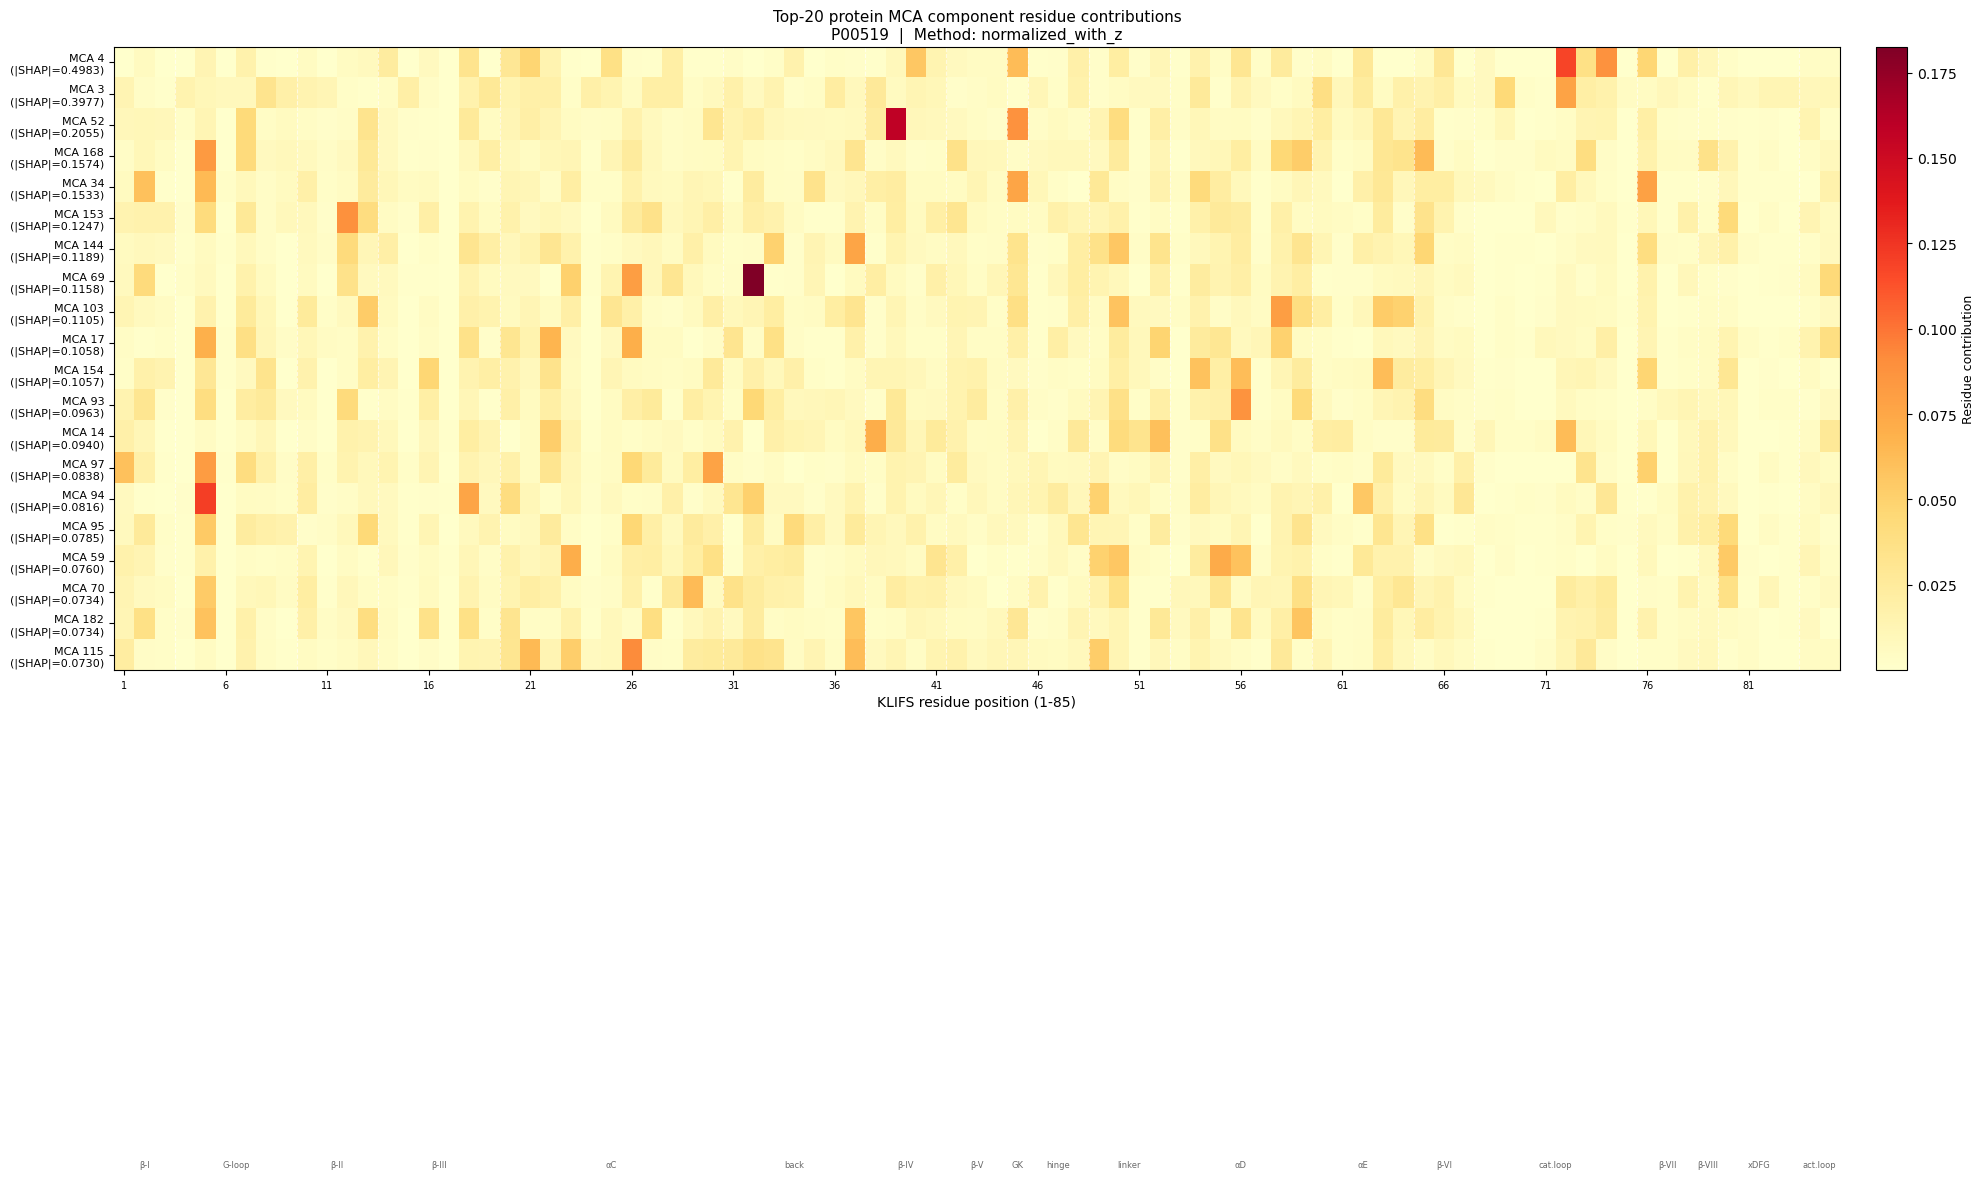


[Validation] Checking contribution conservation (protein):
  MCA 4: |SHAP|=0.4983
  MCA 3: |SHAP|=0.3977
  MCA 52: |SHAP|=0.2055
  MCA 168: |SHAP|=0.1574
  MCA 34: |SHAP|=0.1533

Protein inverse mapping complete!

FINAL SUMMARY - MCA BitScore Analysis
Method: normalized_with_z
Signed version: True

Key improvements:
  ✓ Normalized attribution (contribution conservation)
  ✓ Same scale across MCA components
  ✓ Signed version for mechanistic interpretation
  ✓ Mathematically rigorous


In [9]:
# =========================
# 11) Protein inverse mapping - improved version (normalised + signed), full version
# =========================

print(f"\n{'='*60}")
print(f"Protein Inverse Mapping - MCA BitScore")
print(f"Method: {BITSCORE_METHOD}")
print(f"Signed version: {COMPUTE_SIGNED_BITSCORE}")
print(f"{'='*60}")


BITS_PER_RESIDUE = 23
N_RESIDUES = 1955 // BITS_PER_RESIDUE  # 85 residues

# 23 physicochemical properties encoded by KLIFS
PROPERTY_NAMES = [
    # Sidechain (8)
    "Aliphatic", "Aromatic", "Sulfur", "Imino", "Amide", "Hydroxyl", "Acidic", "Basic",
    # Tertiary Structure (3)
    "Exposed", "Buried", "Intermediate",
    # Functional Property (4)
    "Acidic_func", "Basic_func", "Hydrophobic", "Polar",
    # Secondary Structure Preference (3)
    "alpha_helix", "beta_strand", "Coil",
    # Size (5)
    "Tiny", "Small", "Medium", "Large", "Very_Large"
]

PROPERTY_CATEGORIES = {
    "Sidechain": (0, 8),
    "Tertiary_Structure": (8, 11),
    "Functional_Property": (11, 15),
    "Secondary_Structure": (15, 18),
    "Size": (18, 23)
}

# ---- Load MCA category-to-bit loading matrix ----
mca_base_dir = os.path.dirname(klifs_sae_path)
mca_category_coords_path = os.path.join(mca_base_dir, "MCA_200D_category_coordinates.csv")
mca_category_contrib_path = os.path.join(mca_base_dir, "MCA_200D_category_contributions.csv")
mca_category_lookup_path = os.path.join(mca_base_dir, "MCA_200D_category_lookup.csv")

mca_component_cols = [f"mca_{i+1}" for i in range(prot_emb_used.shape[0])]

mca_coords_df = pd.read_csv(mca_category_coords_path)
mca_contrib_df = pd.read_csv(mca_category_contrib_path)
mca_lookup_df = pd.read_csv(mca_category_lookup_path)

missing_coord_cols = [c for c in mca_component_cols if c not in mca_coords_df.columns]
missing_contrib_cols = [c for c in mca_component_cols if c not in mca_contrib_df.columns]
if missing_coord_cols or missing_contrib_cols:
    raise KeyError(
        "MCA loading files do not contain all protein embedding dimensions. "
        f"Missing coordinates: {missing_coord_cols[:5]}, missing contributions: {missing_contrib_cols[:5]}"
    )


def _normalise_mca_category_name(name):
    return str(name).replace("__", "_")

mca_coords_df = mca_coords_df.copy()
mca_contrib_df = mca_contrib_df.copy()
mca_coords_df["category_name_norm"] = mca_coords_df.iloc[:, 0].map(_normalise_mca_category_name)
mca_contrib_df["category_name_norm"] = mca_contrib_df.iloc[:, 0].map(_normalise_mca_category_name)

coords_by_name = mca_coords_df.set_index("category_name_norm")[mca_component_cols]
contrib_by_name = mca_contrib_df.set_index("category_name_norm")[mca_component_cols]

prot_mca_coord_selected = np.zeros((1955, len(mca_component_cols)), dtype=np.float64)
prot_mca_contrib_selected = np.zeros_like(prot_mca_coord_selected)
missing_mca_categories = []

for _, row in mca_lookup_df.dropna(subset=["bit_index_0_based"]).iterrows():
    bit_idx = int(row["bit_index_0_based"])
    category_name = _normalise_mca_category_name(row["category_name"])
    if category_name not in coords_by_name.index or category_name not in contrib_by_name.index:
        missing_mca_categories.append(category_name)
        continue
    prot_mca_coord_selected[bit_idx] = coords_by_name.loc[category_name].to_numpy(dtype=np.float64)
    prot_mca_contrib_selected[bit_idx] = contrib_by_name.loc[category_name].to_numpy(dtype=np.float64)

# Keep the old variable name for the downstream aggregation code:
# signed MCA category coordinate direction x non-negative MCA contribution magnitude.
prot_Wdec_selected = np.sign(prot_mca_coord_selected) * prot_mca_contrib_selected
prot_z_values = prot_emb_used.astype(np.float64)

print(f"[info] Loaded MCA category loadings: {prot_Wdec_selected.shape[1]} components")
print(f"[info] MCA bit categories with loadings: {np.sum(np.any(prot_mca_contrib_selected > 0, axis=1))} / 1955")
if missing_mca_categories:
    print(f"[WARN] {len(missing_mca_categories)} KLIFS bit categories were absent from the fitted MCA dummy matrix.")
    print(f"       Example missing categories: {missing_mca_categories[:10]}")

print(f"[info] Protein MCA coordinate range: [{prot_z_values.min():.4f}, {prot_z_values.max():.4f}]")

# ---- Read the one-hot sequence of the current protein ----
klifs_onehot_df = pd.read_csv(klifs_onehot_path, header=None)

if row_idx >= len(klifs_onehot_df):
    print(f"[ERROR] row_idx {row_idx} out of range")
else:
    prot_onehot = klifs_onehot_df.iloc[row_idx].values.astype(np.uint8)
    print(f"[info] Protein onehot shape: {prot_onehot.shape}")
    print(f"[info] Active bits: {np.sum(prot_onehot)}")
    
    # ---- Calculate BitScore (unsigned + signed)----
    bit_bitscore_prot_unsigned = np.zeros(1955, dtype=np.float64)
    
    if COMPUTE_SIGNED_BITSCORE:
        bit_bitscore_prot_signed = np.zeros(1955, dtype=np.float64)
    
    # Calculate using the selected method
    if BITSCORE_METHOD == "normalized_with_z":
        print("[info] Using normalized attribution with z_k (protein)")
        
        for lx in important_prot_latents:
            if lx < 0 or lx >= prot_Wdec_selected.shape[1]:
                continue
            
            s_k = prot_shap_values[lx]
            z_k = prot_z_values[lx]
            W_k = prot_Wdec_selected[:, lx]
            
            weighted_loading = prot_onehot * np.abs(z_k) * np.abs(W_k)
            total_loading = np.sum(weighted_loading)
            
            if total_loading > 1e-10:
                normalized_weight = weighted_loading / total_loading
                bit_bitscore_prot_unsigned += np.abs(s_k) * normalized_weight
                
                if COMPUTE_SIGNED_BITSCORE:
                    direction = np.sign(z_k * W_k)
                    bit_bitscore_prot_signed += s_k * normalized_weight * direction
    
    elif BITSCORE_METHOD == "normalized_no_z":
        print("[info] Using normalized attribution without z_k (protein)")
        
        for lx in important_prot_latents:
            if lx < 0 or lx >= prot_Wdec_selected.shape[1]:
                continue
            
            s_k = prot_shap_values[lx]
            W_k = prot_Wdec_selected[:, lx]
            
            weighted_loading = prot_onehot * np.abs(W_k)
            total_loading = np.sum(weighted_loading)
            
            if total_loading > 1e-10:
                normalized_weight = weighted_loading / total_loading
                bit_bitscore_prot_unsigned += np.abs(s_k) * normalized_weight
                
                if COMPUTE_SIGNED_BITSCORE:
                    direction = np.sign(W_k)
                    bit_bitscore_prot_signed += s_k * normalized_weight * direction
    
    else:  # simple_abs
        print("[info] Using simple absolute product (protein)")
        
        for lx in important_prot_latents:
            if lx < 0 or lx >= prot_Wdec_selected.shape[1]:
                continue
            
            s_k = prot_shap_values[lx]
            z_k = prot_z_values[lx]
            W_k = prot_Wdec_selected[:, lx]
            
            bit_bitscore_prot_unsigned += prot_onehot * np.abs(s_k) * np.abs(z_k) * np.abs(W_k)
            
            if COMPUTE_SIGNED_BITSCORE:
                bit_bitscore_prot_signed += prot_onehot * s_k * z_k * W_k
    
    print(f"\n[info] Unsigned BitScore range: [{bit_bitscore_prot_unsigned.min():.6f}, {bit_bitscore_prot_unsigned.max():.6f}]")
    print(f"[info] Bits with unsigned BitScore > 0: {np.sum(bit_bitscore_prot_unsigned > 0)}")
    
    if COMPUTE_SIGNED_BITSCORE:
        print(f"[info] Signed BitScore range: [{bit_bitscore_prot_signed.min():.6f}, {bit_bitscore_prot_signed.max():.6f}]")
        positive_bits = np.sum(bit_bitscore_prot_signed > 0)
        negative_bits = np.sum(bit_bitscore_prot_signed < 0)
        print(f"[info] Signed: {positive_bits} positive, {negative_bits} negative")
    
    # ---- Aggregate by residue ----
    residue_data = []
    
    for res_idx in range(N_RESIDUES):
        start_bit = res_idx * BITS_PER_RESIDUE
        end_bit = start_bit + BITS_PER_RESIDUE
        
        residue_bits = prot_onehot[start_bit:end_bit]
        residue_bitscores_unsigned = bit_bitscore_prot_unsigned[start_bit:end_bit]
        
        total_bitscore_unsigned = np.sum(residue_bitscores_unsigned)
        
        if COMPUTE_SIGNED_BITSCORE:
            residue_bitscores_signed = bit_bitscore_prot_signed[start_bit:end_bit]
            total_bitscore_signed = np.sum(residue_bitscores_signed)
        else:
            total_bitscore_signed = None
        
        # Summarise by the five major categories
        category_scores_unsigned = {}
        category_scores_signed = {} if COMPUTE_SIGNED_BITSCORE else None
        category_active = {}
        
        for cat_name, (cat_start, cat_end) in PROPERTY_CATEGORIES.items():
            cat_bits = residue_bits[cat_start:cat_end]
            cat_scores_unsigned = residue_bitscores_unsigned[cat_start:cat_end]
            category_scores_unsigned[cat_name] = np.sum(cat_scores_unsigned)
            
            if COMPUTE_SIGNED_BITSCORE:
                cat_scores_signed = residue_bitscores_signed[cat_start:cat_end]
                category_scores_signed[cat_name] = np.sum(cat_scores_signed)
            
            category_active[cat_name] = ",".join([
                PROPERTY_NAMES[cat_start + i] 
                for i in range(len(cat_bits)) 
                if cat_bits[i] == 1
            ])
        
        top_category = max(category_scores_unsigned.items(), key=lambda x: x[1])
        
        active_properties = [PROPERTY_NAMES[i] for i in range(BITS_PER_RESIDUE) 
                           if residue_bits[i] == 1]
        
        property_scores = [(PROPERTY_NAMES[i], residue_bitscores_unsigned[i], i) 
                          for i in range(BITS_PER_RESIDUE)]
        property_scores.sort(key=lambda x: x[1], reverse=True)
        
        top_property = property_scores[0] if property_scores[0][1] > 0 else ("none", 0, -1)
        
        # MCA component contribution
        residue_latent_contributions = defaultdict(float)
        
        for lx in important_prot_latents:
            if lx < prot_Wdec_selected.shape[1]:
                s_k = prot_shap_values[lx]
                z_k = prot_z_values[lx]
                W_k_residue = prot_Wdec_selected[start_bit:end_bit, lx]
                residue_bits_slice = prot_onehot[start_bit:end_bit]
                
                if BITSCORE_METHOD.startswith("normalized"):
                    W_k_full = prot_Wdec_selected[:, lx]
                    if "with_z" in BITSCORE_METHOD:
                        weighted_loading = prot_onehot * np.abs(z_k) * np.abs(W_k_full)
                    else:
                        weighted_loading = prot_onehot * np.abs(W_k_full)
                    
                    total_loading = np.sum(weighted_loading)
                    
                    if total_loading > 1e-10:
                        if "with_z" in BITSCORE_METHOD:
                            residue_loading = np.sum(residue_bits_slice * np.abs(z_k) * np.abs(W_k_residue))
                        else:
                            residue_loading = np.sum(residue_bits_slice * np.abs(W_k_residue))
                        
                        contribution = np.abs(s_k) * (residue_loading / total_loading)
                    else:
                        contribution = 0
                else:
                    contribution = np.sum(residue_bits_slice * np.abs(s_k) * np.abs(z_k) * np.abs(W_k_residue))
                
                if contribution > 1e-8:
                    residue_latent_contributions[lx] = contribution
        
        top_latents = sorted(residue_latent_contributions.items(), 
                            key=lambda x: x[1], reverse=True)[:3]
        
        record = {
            "residue_position": res_idx+1,
            "bitscore_unsigned": total_bitscore_unsigned,
            "n_active_properties": len(active_properties),
            "active_properties": ",".join(active_properties) if active_properties else "none",
            "top_property": top_property[0],
            "top_property_score": top_property[1],
            "top_category": top_category[0],
            "top_category_score": top_category[1],
            # unsigned scores for each category
            "Sidechain_unsigned": category_scores_unsigned["Sidechain"],
            "Tertiary_Structure_unsigned": category_scores_unsigned["Tertiary_Structure"],
            "Functional_Property_unsigned": category_scores_unsigned["Functional_Property"],
            "Secondary_Structure_unsigned": category_scores_unsigned["Secondary_Structure"],
            "Size_unsigned": category_scores_unsigned["Size"],
            # active properties for each category
            "Sidechain_active": category_active["Sidechain"],
            "Tertiary_Structure_active": category_active["Tertiary_Structure"],
            "Functional_Property_active": category_active["Functional_Property"],
            "Secondary_Structure_active": category_active["Secondary_Structure"],
            "Size_active": category_active["Size"],
            # MCA component information
            "top_3_components": ",".join([f"{lx}({contrib:.4f})" for lx, contrib in top_latents]),
            "num_contributing_components": len(residue_latent_contributions)
        }
        
        if COMPUTE_SIGNED_BITSCORE:
            record["bitscore_signed"] = total_bitscore_signed
            record["direction"] = "positive" if total_bitscore_signed > 0 else "negative"
            # signed scores for each category
            record["Sidechain_signed"] = category_scores_signed["Sidechain"]
            record["Tertiary_Structure_signed"] = category_scores_signed["Tertiary_Structure"]
            record["Functional_Property_signed"] = category_scores_signed["Functional_Property"]
            record["Secondary_Structure_signed"] = category_scores_signed["Secondary_Structure"]
            record["Size_signed"] = category_scores_signed["Size"]
        
        residue_data.append(record)
    
    df_residue_prot = pd.DataFrame(residue_data).sort_values("bitscore_unsigned", ascending=False)
    df_residue_nonzero = df_residue_prot[df_residue_prot["bitscore_unsigned"] > 0].copy()
    
    residue_csv = os.path.join(outdir, f"prot_residue_bitscore_{BITSCORE_METHOD}.csv")
    df_residue_nonzero.to_csv(residue_csv, index=False)
    print(f"\n[save] Residue BitScore → {residue_csv}")
    
    print(f"\nTop 20 residues (unsigned):")
    display(df_residue_nonzero.head(20))
    
    if COMPUTE_SIGNED_BITSCORE:
        print("\nTop 10 positive residues:")
        df_pos = df_residue_nonzero[df_residue_nonzero["bitscore_signed"] > 0].sort_values("bitscore_signed", ascending=False)
        display(df_pos.head(10))
        
        print("\nTop 10 negative residues:")
        df_neg = df_residue_nonzero[df_residue_nonzero["bitscore_signed"] < 0].sort_values("bitscore_signed", ascending=True)
        display(df_neg.head(10))
    
    # ---- Summarise by property ----
    bit_property_records = []
    
    for bit_idx in range(1955):
        if bit_bitscore_prot_unsigned[bit_idx] > 0:
            residue_idx = bit_idx // BITS_PER_RESIDUE
            property_idx = bit_idx % BITS_PER_RESIDUE
            property_name = PROPERTY_NAMES[property_idx]
            
            category = None
            for cat_name, (start, end) in PROPERTY_CATEGORIES.items():
                if start <= property_idx < end:
                    category = cat_name
                    break
            
            record = {
                "bit": bit_idx,
                "residue_position": residue_idx+1,
                "property_index": property_idx,
                "property_name": property_name,
                "category": category,
                "bitscore_unsigned": bit_bitscore_prot_unsigned[bit_idx],
                "is_active": int(prot_onehot[bit_idx])
            }
            
            if COMPUTE_SIGNED_BITSCORE:
                record["bitscore_signed"] = bit_bitscore_prot_signed[bit_idx]
            
            bit_property_records.append(record)
    
    df_bit_property = pd.DataFrame(bit_property_records).sort_values("bitscore_unsigned", ascending=False)
    bit_csv = os.path.join(outdir, f"prot_bit_bitscore_{BITSCORE_METHOD}.csv")
    df_bit_property.to_csv(bit_csv, index=False)
    print(f"[save] Bit-level BitScore → {bit_csv}")
    
    # Summarise by property
    property_stats = df_bit_property.groupby("property_name").agg({
        "bitscore_unsigned": ["sum", "mean", "count"]
    }).round(6)
    property_stats.columns = ["total_unsigned", "mean_unsigned", "count"]
    
    if COMPUTE_SIGNED_BITSCORE:
        property_stats_signed = df_bit_property.groupby("property_name")["bitscore_signed"].sum()
        property_stats["total_signed"] = property_stats_signed
    
    property_stats = property_stats.sort_values("total_unsigned", ascending=False)
    
    property_csv = os.path.join(outdir, f"prot_property_importance_{BITSCORE_METHOD}.csv")
    property_stats.to_csv(property_csv)
    print(f"[save] Property importance → {property_csv}")
    
    # Summarise by category
    category_stats = df_bit_property.groupby("category").agg({
        "bitscore_unsigned": ["sum", "mean", "count"]
    }).round(6)
    category_stats.columns = ["total_unsigned", "mean_unsigned", "count"]
    
    if COMPUTE_SIGNED_BITSCORE:
        category_stats_signed = df_bit_property.groupby("category")["bitscore_signed"].sum()
        category_stats["total_signed"] = category_stats_signed
    
    category_stats = category_stats.sort_values("total_unsigned", ascending=False)
    
    category_csv = os.path.join(outdir, f"prot_category_importance_{BITSCORE_METHOD}.csv")
    category_stats.to_csv(category_csv)
    print(f"[save] Category importance → {category_csv}")
    
    print("\nTop 10 properties (unsigned):")
    display(property_stats.head(10))
    
    print("\nCategory breakdown (unsigned):")
    display(category_stats)
    


    #----------------------------------------------------------------------------------------------------
    # ---- Summarise the MCA component information distribution ---
    # ---- Domain mapping ----
    KLIFS_DOMAIN_MAP = {}
    for i in range(0, 3):    KLIFS_DOMAIN_MAP[i] = "beta-strand_I"
    for i in range(3, 9):    KLIFS_DOMAIN_MAP[i] = "glycine-rich_loop"
    for i in range(9, 13):   KLIFS_DOMAIN_MAP[i] = "beta-strand_II"
    for i in range(13, 19):  KLIFS_DOMAIN_MAP[i] = "beta-strand_III"
    for i in range(19, 30):  KLIFS_DOMAIN_MAP[i] = "alphaC-helix"
    for i in range(30, 37):  KLIFS_DOMAIN_MAP[i] = "back_loop"
    for i in range(37, 41):  KLIFS_DOMAIN_MAP[i] = "beta-strand_IV"
    for i in range(41, 44):  KLIFS_DOMAIN_MAP[i] = "beta-strand_V"
    KLIFS_DOMAIN_MAP[44]     = "Gatekeeper"
    for i in range(45, 48):  KLIFS_DOMAIN_MAP[i] = "hinge_region"
    for i in range(48, 52):  KLIFS_DOMAIN_MAP[i] = "linker"
    for i in range(52, 59):  KLIFS_DOMAIN_MAP[i] = "alphaD-helix"
    for i in range(59, 64):  KLIFS_DOMAIN_MAP[i] = "alphaE-helix"
    for i in range(64, 67):  KLIFS_DOMAIN_MAP[i] = "beta-strand_VI"
    for i in range(67, 75):  KLIFS_DOMAIN_MAP[i] = "catalytic_loop"
    for i in range(75, 78):  KLIFS_DOMAIN_MAP[i] = "beta-strand_VII"
    KLIFS_DOMAIN_MAP[78]     = "beta-strand_VIII"
    for i in range(79, 83):  KLIFS_DOMAIN_MAP[i] = "xDFG"
    for i in range(83, 85):  KLIFS_DOMAIN_MAP[i] = "activation_loop"

    # ---- Top-10 residue to domain analysis for each important MCA component ----
    latent_domain_records = []
    domain_freq_counter = defaultdict(int)   # domain frequency across all MCA components

    for lx in important_prot_latents:
        if lx >= prot_Wdec_selected.shape[1]:
            continue

        s_k = prot_shap_values[lx]
        z_k = prot_z_values[lx]
        W_k = prot_Wdec_selected[:, lx]

        # Calculate the contribution of this MCA component at each residue (consistent with the main BitScore loop)
        residue_contrib = np.zeros(N_RESIDUES, dtype=np.float64)

        if BITSCORE_METHOD.startswith("normalized"):
            if "with_z" in BITSCORE_METHOD:
                weighted_loading = prot_onehot * np.abs(z_k) * np.abs(W_k)
            else:
                weighted_loading = prot_onehot * np.abs(W_k)
            total_loading = np.sum(weighted_loading)

            if total_loading > 1e-10:
                for res_idx in range(N_RESIDUES):
                    s = res_idx * BITS_PER_RESIDUE
                    e = s + BITS_PER_RESIDUE
                    if "with_z" in BITSCORE_METHOD:
                        r_load = np.sum(prot_onehot[s:e] * np.abs(z_k) * np.abs(W_k[s:e]))
                    else:
                        r_load = np.sum(prot_onehot[s:e] * np.abs(W_k[s:e]))
                    residue_contrib[res_idx] = np.abs(s_k) * (r_load / total_loading)
        else:
            for res_idx in range(N_RESIDUES):
                s = res_idx * BITS_PER_RESIDUE
                e = s + BITS_PER_RESIDUE
                residue_contrib[res_idx] = np.sum(
                    prot_onehot[s:e] * np.abs(s_k) * np.abs(z_k) * np.abs(W_k[s:e])
                )

        # top 10 residues
        top10_idx = np.argsort(residue_contrib)[::-1][:10]

        for rank, res_idx in enumerate(top10_idx):
            contrib_val = residue_contrib[res_idx]
            if contrib_val < 1e-10:
                break
            domain = KLIFS_DOMAIN_MAP.get(res_idx, "unknown")
            domain_freq_counter[domain] += 1

            latent_domain_records.append({
                "component_index": lx,
                "shap_value": s_k,
                "abs_shap": np.abs(s_k),
                "rank": rank + 1,
                "residue_position": res_idx+1,
                "residue_position_1indexed": res_idx + 1,
                "domain": domain,
                "residue_contrib": contrib_val
            })

    df_latent_domain = pd.DataFrame(latent_domain_records)

    latent_domain_csv = os.path.join(outdir, f"prot_mca_component_top10_domains_{BITSCORE_METHOD}.csv")
    df_latent_domain.to_csv(latent_domain_csv, index=False)
    print(f"[save] MCA component→domain mapping → {latent_domain_csv}")

    # ---- Domain-frequency summary across all latents ----
    df_domain_freq = pd.DataFrame([
        {"domain": k, "freq": v} for k, v in domain_freq_counter.items()
    ]).sort_values("freq", ascending=False)

    # Add the mean contribution for each domain
    domain_mean_contrib = (
        df_latent_domain.groupby("domain")["residue_contrib"]
        .mean()
        .rename("mean_contrib")
    )
    df_domain_freq = df_domain_freq.set_index("domain").join(domain_mean_contrib).reset_index()
    df_domain_freq = df_domain_freq.sort_values("freq", ascending=False)

    domain_freq_csv = os.path.join(outdir, f"prot_domain_frequency_{BITSCORE_METHOD}.csv")
    df_domain_freq.to_csv(domain_freq_csv, index=False)
    print(f"[save] Domain frequency → {domain_freq_csv}")

    print(f"\nDomain frequency across all important MCA components (top10 residues each):")
    print(df_domain_freq.to_string(index=False))

    # ---- Domain distribution for each MCA component (pivot)----
    if len(df_latent_domain) > 0:
        latent_domain_pivot = (
            df_latent_domain.groupby(["component_index", "domain"])
            .size()
            .unstack(fill_value=0)
        )
        pivot_csv = os.path.join(outdir, f"prot_mca_component_domain_pivot_{BITSCORE_METHOD}.csv")
        latent_domain_pivot.to_csv(pivot_csv)
        print(f"[save] MCA component×domain pivot → {pivot_csv}")

    # ---- Plot MCA component heatmap ----
# ---- Top-20 important protein MCA components - residue contribution heatmap ----

    top20_latents = np.argsort(-prot_abs_shap)[:20].tolist()
    heatmap_data = np.zeros((20, N_RESIDUES), dtype=np.float64)

    for row_i, lx in enumerate(top20_latents):
        z_k = prot_z_values[lx]
        W_k = prot_Wdec_selected[:, lx]

        residue_contrib = np.zeros(N_RESIDUES, dtype=np.float64)

        if "with_z" in BITSCORE_METHOD:
            weighted_loading = prot_onehot * np.abs(z_k) * np.abs(W_k)
        else:
            weighted_loading = prot_onehot * np.abs(W_k)

        total_loading = np.sum(weighted_loading)

        if total_loading > 1e-10:
            for res_idx in range(N_RESIDUES):
                s = res_idx * BITS_PER_RESIDUE
                e = s + BITS_PER_RESIDUE
                if "with_z" in BITSCORE_METHOD:
                    r_load = np.sum(prot_onehot[s:e] * np.abs(z_k) * np.abs(W_k[s:e]))
                else:
                    r_load = np.sum(prot_onehot[s:e] * np.abs(W_k[s:e]))
                residue_contrib[res_idx] = r_load / total_loading

        heatmap_data[row_i] = residue_contrib

    # ---- Domain-boundary annotation ----
    DOMAIN_BOUNDARIES = [
        (0,  2,  "β-I"),
        (3,  8,  "G-loop"),
        (9,  12, "β-II"),
        (13, 18, "β-III"),
        (19, 29, "αC"),
        (30, 36, "back"),
        (37, 40, "β-IV"),
        (41, 43, "β-V"),
        (44, 44, "GK"),
        (45, 47, "hinge"),
        (48, 51, "linker"),
        (52, 58, "αD"),
        (59, 63, "αE"),
        (64, 66, "β-VI"),
        (67, 74, "cat.loop"),
        (75, 77, "β-VII"),
        (78, 78, "β-VIII"),
        (79, 82, "xDFG"),
        (83, 84, "act.loop"),
    ]

    fig, ax = plt.subplots(figsize=(20, 18))

    im = ax.imshow(
        heatmap_data,
        aspect="auto",
        cmap="YlOrRd",
        interpolation="nearest"
    )

    # y-axis: MCA component labels
    y_labels = [
        f"MCA {lx+1}\n(|SHAP|={np.abs(prot_shap_values[lx]):.4f})"
        for lx in top20_latents
    ]
    ax.set_yticks(range(20))
    ax.set_yticklabels(y_labels, fontsize=8)

    # x-axis: residue positions
    ax.set_xticks(range(0, N_RESIDUES, 5))
    ax.set_xticklabels(range(1, N_RESIDUES + 1, 5), fontsize=7)
    ax.set_xlabel("KLIFS residue position (1-85)", fontsize=10)

    # Vertical lines for domain boundaries + top labels
    for start, end, label in DOMAIN_BOUNDARIES:
        # Left-boundary vertical line
        if start > 0:
            ax.axvline(x=start - 0.5, color="white", linewidth=0.8, linestyle="--", alpha=0.6)
        # Place the domain name at the top
        mid = (start + end) / 2
        ax.text(
            mid, -0.8, label,
            ha="center", va="bottom",
            fontsize=6, color="dimgray",
            transform=ax.get_xaxis_transform()
        )

    cbar = plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
    cbar.set_label("Residue contribution", fontsize=9)

    ax.set_title(
        f"Top-20 protein MCA component residue contributions\n"
        f"{kinase_name}  |  Method: {BITSCORE_METHOD}",
        fontsize=11
    )

    plt.tight_layout()
    heatmap_path = os.path.join(outdir, f"prot_top20_mca_component_heatmap_{BITSCORE_METHOD}.png")
    plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
    print(f"[save] Top-20 MCA component heatmap → {heatmap_path}")
    plt.show()


    # ---- Contribution-conservation validation ----
    if BITSCORE_METHOD.startswith("normalized"):
        print("\n[Validation] Checking contribution conservation (protein):")
        
        for idx, lx in enumerate(important_prot_latents[:5]):
            if lx < prot_Wdec_selected.shape[1]:
                s_k = prot_shap_values[lx]
                
                # Calculate the total attributed contribution of this MCA component
                total_contrib = 0
                for res_idx in range(N_RESIDUES):
                    start_bit = res_idx * BITS_PER_RESIDUE
                    end_bit = start_bit + BITS_PER_RESIDUE
                    total_contrib += np.sum(bit_bitscore_prot_unsigned[start_bit:end_bit])
                
                # This calculation is duplicated and needs correction
                # Use the bit-level sum directly
                W_k = prot_Wdec_selected[:, lx]
                z_k = prot_z_values[lx]
                
                if "with_z" in BITSCORE_METHOD:
                    weighted_loading = prot_onehot * np.abs(z_k) * np.abs(W_k)
                else:
                    weighted_loading = prot_onehot * np.abs(W_k)
                
                total_loading = np.sum(weighted_loading)
                
                if total_loading > 1e-10:
                    expected_contrib = np.abs(s_k)
                    print(f"  MCA {lx+1}: |SHAP|={expected_contrib:.4f}")
                else:
                    print(f"  MCA {lx+1}: No contribution (zero loading)")

print(f"\n{'='*60}")
print(f"Protein inverse mapping complete!")
print(f"{'='*60}")

# ---- Final summary ----
print(f"\n{'='*60}")
print(f"FINAL SUMMARY - MCA BitScore Analysis")
print(f"{'='*60}")
print(f"Method: {BITSCORE_METHOD}")
print(f"Signed version: {COMPUTE_SIGNED_BITSCORE}")
print(f"\nKey improvements:")
print(f"  ✓ Normalized attribution (contribution conservation)")
print(f"  ✓ Same scale across MCA components")
print(f"  ✓ Signed version for mechanistic interpretation")
print(f"  ✓ Mathematically rigorous")
print(f"{'='*60}")